In [1]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts()

In [2]:
md_blood_5p  <- read_csv("../241201_VN_PREDICT2/data/metadata/250113_Blood_5p_metadata.csv")

New names:
• `` -> `...1`
Rows: 593574 Columns: 91
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (62): ...1, orig.ident, SingleR_HPCA, data_folder, barcode, sample, diag...
dbl (21): nCount_RNA, nFeature_RNA, percent.mt, percent.rt, RNA_snn_res.0.3,...
lgl  (8): cd4_ctl, is_cell, count_Multi, cdr3_Multi, cdr3_Multi_nt, v_gene_M...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
md_blood_5p  %>% colnames

[1] "...1"                    "orig.ident"             
 [3] "nCount_RNA"              "nFeature_RNA"           
 [5] "percent.mt"              "percent.rt"             
 [7] "SingleR_HPCA"            "data_folder"            
 [9] "RNA_snn_res.0.3"         "seurat_clusters"        
[11] "barcode"                 "integrated_snn_res.0.4" 
[13] "sample"                  "diagnosis"              
[15] "subgroup_primary"        "subgroup_secondary"     
[17] "subgroup_tertiary"       "Rome_coarse"            
[19] "Rome_classification"     "antitnf_response"       
[21] "participant_id"          "timepoint"              
[23] "age"                     "sex"                    
[25] "site"                    "tissue"                 
[27] "layer"                   "prime"                  
[29] "version_10x"             "sample_old"             
[31] "data_type"               "seq_run"                
[33] "collection_purpose"      "collection_date"        
[35] "days"                    "antitnf"                
[37] "antitnf_repeat"          "duo_inflammation"       
[39] "ile_inflammation"        "col_inflammation"       
[41] "sample_inflamed"         "colon_site"             
[43] "score_type"              "severity_score"         
[45] "weighted_severity_score" "severity_score_date"    
[47] "severity_score_range"    "weighted_score_range"   
[49] "internal_flag"           "integrated_snn_res.0.6" 
[51] "integrated_snn_res.0.7"  "cluster_subclust1"      
[53] "annot_subclust"          "seurat_clusters2"       
[55] "annotations"             "subclust_vsm_res05"     
[57] "cd4_ctl"                 "is_cell"                
[59] "chain"                   "contig_id"              
[61] "high_confidence"         "productive"             
[63] "length"                  "reads"                  
[65] "umis"                    "count_TRA"              
[67] "count_TRB"               "count_Multi"            
[69] "cdr3_A1"                 "cdr3_A1_nt"             
[71] "cdr3_A2"                 "cdr3_A2_nt"             
[73] "cdr3_B"                  "cdr3_B_nt"              
[75] "cdr3_Multi"              "cdr3_Multi_nt"          
[77] "v_gene_A1"               "j_gene_A1"              
[79] "v_gene_A2"               "j_gene_A2"              
[81] "v_gene_B"                "d_gene_B"               
[83] "j_gene_B"                "v_gene_Multi"           
[85] "d_gene_Multi"            "j_gene_Multi"           
[87] "clone_nt"                "clone_aa"               
[89] "test"                    "clone_abundance"        
[91] "log_clone_abundance"

In [4]:
md_blood_5p$cd4_ctl  %>% table

.
 FALSE   TRUE 
591958   1616 

In [27]:
seu  <- md_blood_5p

In [ ]:
# Step 1 - save amino acid sequences of TCRb to a txt file

In [21]:
md_blood_5p$cdr3_B  %>% head

[1] "CASSSVRTGRMNTEAFF" NA                  "CASSQSRGGNTIYF"   
[4] "CSVEGTSDEQYF"      "CASSLPGQVAGTEAFF"  "CASSQVYGTSGIF"

In [8]:
tcrb2 <- as.data.frame(unique(md_blood_5p$cdr3_B))  

colnames(tcrb2) = "seq"

tcrb2  <-  tcrb2 %>% dplyr::filter(seq != "NA")

write_delim(tcrb2, delim = "\t", quote = "none", col_names = F, 
            file = "../241201_VN_PREDICT2/blood_5p_tcrb_for_tcrmatch.csv")

In [9]:
tcrb2

seq
<chr>
CASSPGWANEKLFF
CASRPTGSPTEAFF
CASSYSTGGTEAFF
CASRPALGVGYTF
CASSYALTGDTEAFF
CASSLAQSMNTEAFF
CASSRAGLRETQYF
CSADISGANVLTF
CASSRRDTSGANVLTF


In [ ]:
# Step 2 - run the TCRMatch algorithm


This code should be run in bash:

`./tcrmatch -i ./input/tcrb_fpies.txt -t 12 -d ./data/IEDB_data.tsv  > ./output/fpies_output_iedb.tsv`

`./tcrmatch -i ./input/tcrb_fpies.txt -t 12 -d ./data/CEDAR_data.tsv  > ./output/fpies_output_cedar.tsv`


In [ ]:
# Step 3 - load the outputs

In [22]:
blood_5p_output_iedb  <- read_delim("../241201_VN_PREDICT2/data/tcrmatch/blood_5p_output_IEDB.tsv", delim = "\t")

Rows: 73206 Columns: 7
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (5): trimmed_input_sequence, match_sequence, epitope, antigen, organism
dbl (2): score, receptor_group

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [23]:
seu$cdr3_B %in% blood_5p_output_iedb$trimmed_input_sequence  %>% table

.
FALSE 
 1616 

In [30]:
## Need to trim cdr3_b sequence

In [24]:
seu$trimmed_input_sequence  <- substr(seu$cdr3_B,2,nchar(seu$cdr3_B)-1)

In [25]:
seu$trimmed_input_sequence %in% blood_5p_output_iedb$trimmed_input_sequence  %>% table

.
FALSE  TRUE 
 1403   213 

In [52]:
seu

...1,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,percent.rt,SingleR_HPCA,data_folder,RNA_snn_res.0.3,seurat_clusters,⋯,d_gene_B,j_gene_B,v_gene_Multi,d_gene_Multi,j_gene_Multi,clone_nt,clone_aa,test,clone_abundance,log_clone_abundance
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,⋯,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
AAACCTGAGAGATGAG-1_1_1_1,SeuratProject,1311,832,4.950166,46.24585,T_cells,1740278_1_1_1,2,1,⋯,NA,TRBJ1-1,NA,NA,NA,TGTGCCAGCTCGTCTGTGAGGACAGGGAGGATGAACACTGAAGCTTTCTTT TGTGCTCTGAGTGAGGCTCATAATGCAGGCAACATGCTCACCTTT NA,CDR3b CASSSVRTGRMNTEAFF CDR3a CALSEAHNAGNMLTF,0,2,1
AAACCTGAGAGTACCG-1_1_1_1,SeuratProject,5018,2341,4.287179,39.94872,T_cells,1740278_1_1_1,9,6,⋯,NA,NA,NA,NA,NA,NA TGTGCAAAATGGGGGGATAGCAGCTATAAATTGATCTTC NA,CDR3b NA CDR3a CAKWGDSSYKLIF,0,1,0
AAACCTGAGAGTGAGA-1_1_1_1,SeuratProject,6878,2999,2.692489,27.45394,T_cells,1740278_1_1_1,5,2,⋯,NA,TRBJ1-3,NA,NA,NA,TGTGCCAGCAGCCAATCCAGGGGTGGAAACACCATATATTTT TGTGCAGCAAGCAATTCAGGAAACACACCTCTTGTCTTT NA,CDR3b CASSQSRGGNTIYF CDR3a CAASNSGNTPLVF,0,1,0
AAACCTGAGCTGAACG-1_1_1_1,SeuratProject,3977,2048,4.266118,36.89986,T_cells,1740278_1_1_1,9,6,⋯,NA,TRBJ2-7,NA,NA,NA,TGCAGCGTTGAGGGTACTAGCGACGAGCAGTACTTC TGTGCAGGAGCGGGGGATAACTATGGTCAGAATTTTGTCTTT NA,CDR3b CSVEGTSDEQYF CDR3a CAGAGDNYGQNFVF,0,1,0
AAACCTGAGGCAATTA-1_1_1_1,SeuratProject,4910,2442,2.917505,37.39101,T_cells,1740278_1_1_1,0,0,⋯,TRBD1,TRBJ1-1,NA,NA,NA,TGCGCCAGCAGCTTACCGGGACAGGTAGCTGGTACTGAAGCTTTCTTT TGTGCTGTGAGTGACCAAGCTGCAGGCAACAAGCTAACTTTT NA,CDR3b CASSLPGQVAGTEAFF CDR3a CAVSDQAAGNKLTF,0,1,0
AAACCTGAGGCTAGAC-1_1_1_1,SeuratProject,3547,1819,5.058939,31.49967,T_cells,1740278_1_1_1,0,5,⋯,TRBD2,TRBJ2-5,NA,NA,NA,TGCGCCAGCAGCCAAGTGTATGGGACTAGCGGGATCTTC TGTGCTACGTTAAGGGATACTGGAGGCTTCAAAACTATCTTT TGTGCTCCCCGTGTCCCGTATAACTTTGGAAATGAGAAATTAACCTTT,CDR3b CASSQVYGTSGIF CDR3a CATLRDTGGFKTIF,0,1,0
AAACCTGAGTAGCCGA-1_1_1_1,SeuratProject,4676,2315,4.156266,33.64953,T_cells,1740278_1_1_1,1,3,⋯,NA,TRBJ1-3,NA,NA,NA,TGCAGTGCACCGGCCCCAGGGGCAGGAAACACCATATATTTT TGTGCTGTGAGGGGCTCTAGCAACACAGGCAAACTAATCTTT NA,CDR3b CSAPAPGAGNTIYF CDR3a CAVRGSSNTGKLIF,0,1,0
AAACCTGCAACTGCGC-1_1_1_1,SeuratProject,4562,2242,3.449048,40.97424,T_cells,1740278_1_1_1,10,5,⋯,NA,TRBJ2-1,NA,NA,NA,TGTGCCAGCAGGGTAGCGGGAGGTCGGCGGGGCTACAATGAGCAGTTCTTC NA NA,CDR3b CASRVAGGRRGYNEQFF CDR3a NA,0,1,0
AAACCTGCAACTTGAC-1_1_1_1,SeuratProject,3303,1851,3.241120,38.90981,T_cells,1740278_1_1_1,0,2,⋯,NA,TRBJ2-3,NA,NA,NA,TGCGCCAGCAGCTTGGTGGCTAGCGGCACAGATACGCAGTATTTT TGTGCAGCAACCTCAGGAACCTACAAATACATCTTT NA,CDR3b CASSLVASGTDTQYF CDR3a CAATSGTYKYIF,0,1,0


In [15]:
md_blood_5p  <- seu  %>% left_join(blood_5p_output_iedb)

Joining with `by = join_by(trimmed_input_sequence)`
Warning message in left_join(., cd4_ctl_blood_output_iedb):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 4 of `x` matches multiple rows in `y`.
ℹ Row 10043 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


In [16]:
md_blood_5p

...1,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,percent.rt,SingleR_HPCA,data_folder,RNA_snn_res.0.3,seurat_clusters,⋯,test,clone_abundance,log_clone_abundance,trimmed_input_sequence,match_sequence,score,receptor_group,epitope,antigen,organism
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
ACTTTCATCGGAAATA-1_1_1_1,SeuratProject,7292,3073,4.367355,19.85856,T_cells,1740278_1_1_1,1,12,⋯,0,1,0.000000,ASSPGWANEKLF,NA,NA,NA,NA,NA,NA
AGCGGTCTCGGTGTTA-1_1_1_1,SeuratProject,4700,2219,3.656620,21.36838,T_cells,1740278_1_1_1,1,12,⋯,0,1,0.000000,NA,NA,NA,NA,NA,NA,NA
CCCAGTTTCCTCGCAT-1_1_1_1,SeuratProject,4631,2221,2.299908,21.38914,T_cells,1740278_1_1_1,1,12,⋯,0,1,0.000000,ASRPTGSPTEAF,NA,NA,NA,NA,NA,NA
CCTTTCTAGAGAGCTC-1_1_1_1,SeuratProject,11977,3926,4.574970,17.26682,T_cells,1740278_1_1_1,1,12,⋯,0,1,0.000000,ASSYSTGGTEAF,ASSFSTGGTEAF,0.977275,82100,RNPANNAAIVL,nucleocapsid phosphoprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
CCTTTCTAGAGAGCTC-1_1_1_1,SeuratProject,11977,3926,4.574970,17.26682,T_cells,1740278_1_1_1,1,12,⋯,0,1,0.000000,ASSYSTGGTEAF,ASSYSSGGTEAF,0.978332,135801,TLIGDCATV,orf1ab polyprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
CCTTTCTAGAGAGCTC-1_1_1_1,SeuratProject,11977,3926,4.574970,17.26682,T_cells,1740278_1_1_1,1,12,⋯,0,1,0.000000,ASSYSTGGTEAF,ASSYTTGGTEAF,0.978531,135840,TLIGDCATV,orf1ab polyprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
CCTTTCTAGAGAGCTC-1_1_1_1,SeuratProject,11977,3926,4.574970,17.26682,T_cells,1740278_1_1_1,1,12,⋯,0,1,0.000000,ASSYSTGGTEAF,ASSYSTGGTEAF,1.000000,136261,TLIGDCATV,orf1ab polyprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
CGGAGCTAGACAAGCC-1_1_1_1,SeuratProject,14165,4256,3.216866,26.81630,T_cells,1740278_1_1_1,1,12,⋯,0,1,0.000000,ASRPALGVGYT,NA,NA,NA,NA,NA,NA
CTCACACAGCAAATCA-1_1_1_1,SeuratProject,4867,2310,2.924058,24.47339,T_cells,1740278_1_1_1,1,12,⋯,0,1,0.000000,ASSYALTGDTEAF,NA,NA,NA,NA,NA,NA


Need to correct that some sequences are duplicated. 

In [28]:
blood_5p_output_iedb$trimmed_input_sequence  %>% duplicated  %>% table

.
FALSE  TRUE 
41572 31634 

In [29]:
just_organism  <- blood_5p_output_iedb  %>% dplyr::select(trimmed_input_sequence, organism)  %>% unique

In [30]:
just_organism$trimmed_input_sequence  %>% duplicated  %>% table

.
FALSE  TRUE 
41572 19653 

19653 sequences are specific to multiple organisms

Let's filter the hits with the highest score for those. 

In [31]:
blood_5p_output_iedb_noDupl  <- blood_5p_output_iedb  %>% group_by(trimmed_input_sequence)  %>% 
slice_max(order_by = score, n = 1, with_ties = F)

In [32]:
blood_5p_output_iedb_noDupl$trimmed_input_sequence  %>% duplicated  %>% table

.
FALSE 
41572 

In [33]:
blood_5p_output_iedb_noDupl

trimmed_input_sequence,match_sequence,score,receptor_group,epitope,antigen,organism
<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
AAASAGETQY,ASAASGETQY,0.970554,69401,MGYINVFAFPFTIYSL,ORF10 protein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AAASTDTQY,ASASTDTQY,0.987106,69527,"IMLIIFWFSL,MIELSLIDFYLCFLAFLLFLVLIML","ORF7b [Severe acute respiratory syndrome coronavirus 2],ORF7b [Severe acute respiratory syndrome coronavirus 2]","SARS-CoV2,SARS-CoV2"
AADRGGYEQY,ASDRGGYEQY,0.984995,69664,AYSNNSIAIPTNFTISV,surface glycoprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AADTQY,ASDTQY,0.979995,69690,RSVASQSIIAYTMSL,surface glycoprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AAGELF,SAGELF,0.987773,8516,QYDPVAALF,tegument protein pp65,Human herpesvirus 5 (Human cytomegalovirus)
AAGGGEQY,ASGGGEQF,0.973967,70132,FVDGVPFVV,orf1ab polyprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AAGGGGQPQH,SVGGGGQPQH,0.972850,10568,NLVPMVATV,HCMVUL83,Human herpesvirus 5 (Human cytomegalovirus)
AAGGGLYEQY,ASGGGLYEQY,0.985861,15513,GILGFVFTL,Matrix protein 1,Influenza A virus
AAGGHEQF,AGGGHEQF,0.974235,205182,RVRAYTYSK,Replication and transcription activator,Human herpesvirus 4 strain B95-8 (Epstein-Barr virus (strain B95-8))


In [36]:
md_blood_5p$trimmed_input_sequence  <- substr(md_blood_5p$cdr3_B,2,nchar(md_blood_5p$cdr3_B)-1)

In [38]:
md_blood_5p  <- md_blood_5p  %>% left_join(blood_5p_output_iedb_noDupl)

Joining with `by = join_by(trimmed_input_sequence)`


In [39]:
md_blood_5p

...1,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,percent.rt,SingleR_HPCA,data_folder,RNA_snn_res.0.3,seurat_clusters,⋯,test,clone_abundance,log_clone_abundance,trimmed_input_sequence,match_sequence,score,receptor_group,epitope,antigen,organism
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
AAACCTGAGAGATGAG-1_1_1_1,SeuratProject,1311,832,4.950166,46.24585,T_cells,1740278_1_1_1,2,1,⋯,0,2,1,ASSSVRTGRMNTEAF,NA,NA,NA,NA,NA,NA
AAACCTGAGAGTACCG-1_1_1_1,SeuratProject,5018,2341,4.287179,39.94872,T_cells,1740278_1_1_1,9,6,⋯,0,1,0,NA,NA,NA,NA,NA,NA,NA
AAACCTGAGAGTGAGA-1_1_1_1,SeuratProject,6878,2999,2.692489,27.45394,T_cells,1740278_1_1_1,5,2,⋯,0,1,0,ASSQSRGGNTIY,NA,NA,NA,NA,NA,NA
AAACCTGAGCTGAACG-1_1_1_1,SeuratProject,3977,2048,4.266118,36.89986,T_cells,1740278_1_1_1,9,6,⋯,0,1,0,SVEGTSDEQY,NA,NA,NA,NA,NA,NA
AAACCTGAGGCAATTA-1_1_1_1,SeuratProject,4910,2442,2.917505,37.39101,T_cells,1740278_1_1_1,0,0,⋯,0,1,0,ASSLPGQVAGTEAF,NA,NA,NA,NA,NA,NA
AAACCTGAGGCTAGAC-1_1_1_1,SeuratProject,3547,1819,5.058939,31.49967,T_cells,1740278_1_1_1,0,5,⋯,0,1,0,ASSQVYGTSGI,NA,NA,NA,NA,NA,NA
AAACCTGAGTAGCCGA-1_1_1_1,SeuratProject,4676,2315,4.156266,33.64953,T_cells,1740278_1_1_1,1,3,⋯,0,1,0,SAPAPGAGNTIY,NA,NA,NA,NA,NA,NA
AAACCTGCAACTGCGC-1_1_1_1,SeuratProject,4562,2242,3.449048,40.97424,T_cells,1740278_1_1_1,10,5,⋯,0,1,0,ASRVAGGRRGYNEQF,NA,NA,NA,NA,NA,NA
AAACCTGCAACTTGAC-1_1_1_1,SeuratProject,3303,1851,3.241120,38.90981,T_cells,1740278_1_1_1,0,2,⋯,0,1,0,ASSLVASGTDTQY,ASSLLASGTDTQY,0.979610,100683,RNPANNAAIVL,nucleocapsid phosphoprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2


In [40]:
md_blood_5p$annotations  %>% table

.
 CD4_Central_Memory           CD4_Naive   CD4_Teff_Th1/Th17        CD4_Teff_Th2 
              57801              196865               17326               62393 
 CD4_Treg_Activated      CD4_Treg_Naive  CD8_Central_Memory CD8_Effector_Memory 
              12014               17024               27184               39620 
          CD8_Naive             CD8_Tgd              ISAGhi            NK_cells 
             106441               25271                4840               22902 
      Proliferating 
               3893 

In [41]:
md_blood_5p$annot_and_cd4_ctl  <- if_else(md_blood_5p$cd4_ctl, "CD4 CTL", md_blood_5p$annotations)

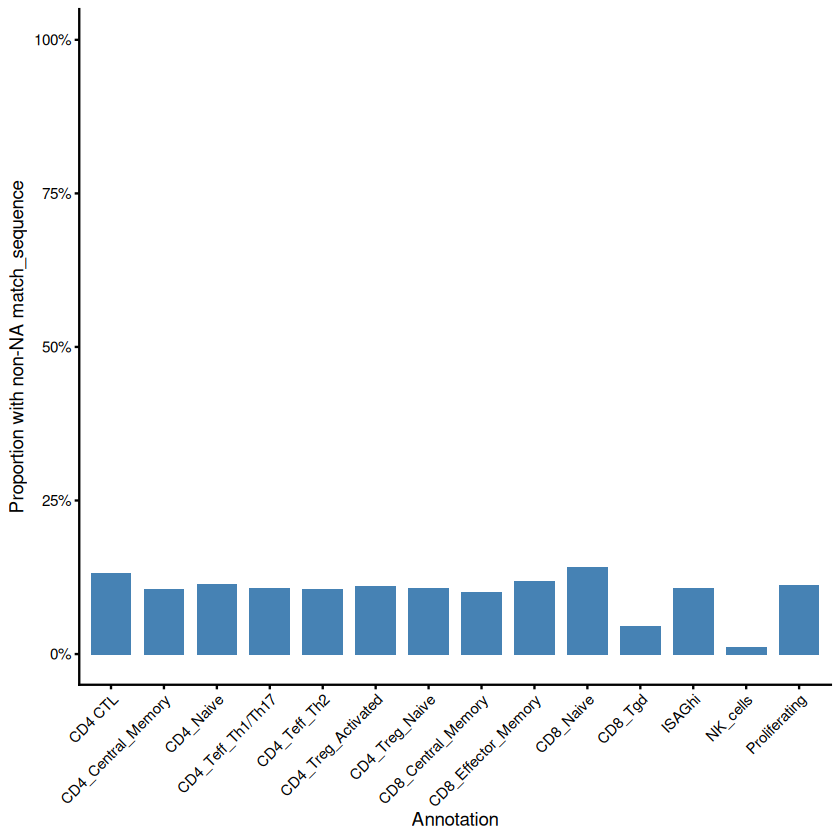

In [43]:
library(dplyr)
library(ggplot2)

plot_df <- md_blood_5p %>%
  group_by(annot_and_cd4_ctl) %>%
  summarise(
    n_total = n(),
    n_matched = sum(!is.na(match_sequence)),
    proportion = n_matched / n_total,
    .groups = "drop"
  )

ggplot(plot_df, aes(x = annot_and_cd4_ctl, y = proportion)) +
  geom_col(fill = "steelblue", width = 0.75) +
  scale_y_continuous(
    labels = scales::label_percent(),
    limits = c(0, 1)
  ) +
  labs(
    x = "Annotation",
    y = "Proportion with non-NA match_sequence"
  ) +
  theme_classic() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

In [45]:
md_blood_5p  %>% group_by(organism)  %>% tally()  %>% arrange(desc(n))

organism,n
<chr>,<int>
NA,530286
SARS-CoV2,32269
Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169)),4196
"SARS-CoV2,SARS-CoV2",3067
Human herpesvirus 4 (Epstein Barr virus),2907
Human herpesvirus 5 (Human cytomegalovirus),2014
Influenza A virus,1838
Hepatitis B virus (Human hepatitis B virus),1332
"Influenza A virus,Human herpesvirus 5 (Human cytomegalovirus)",1042


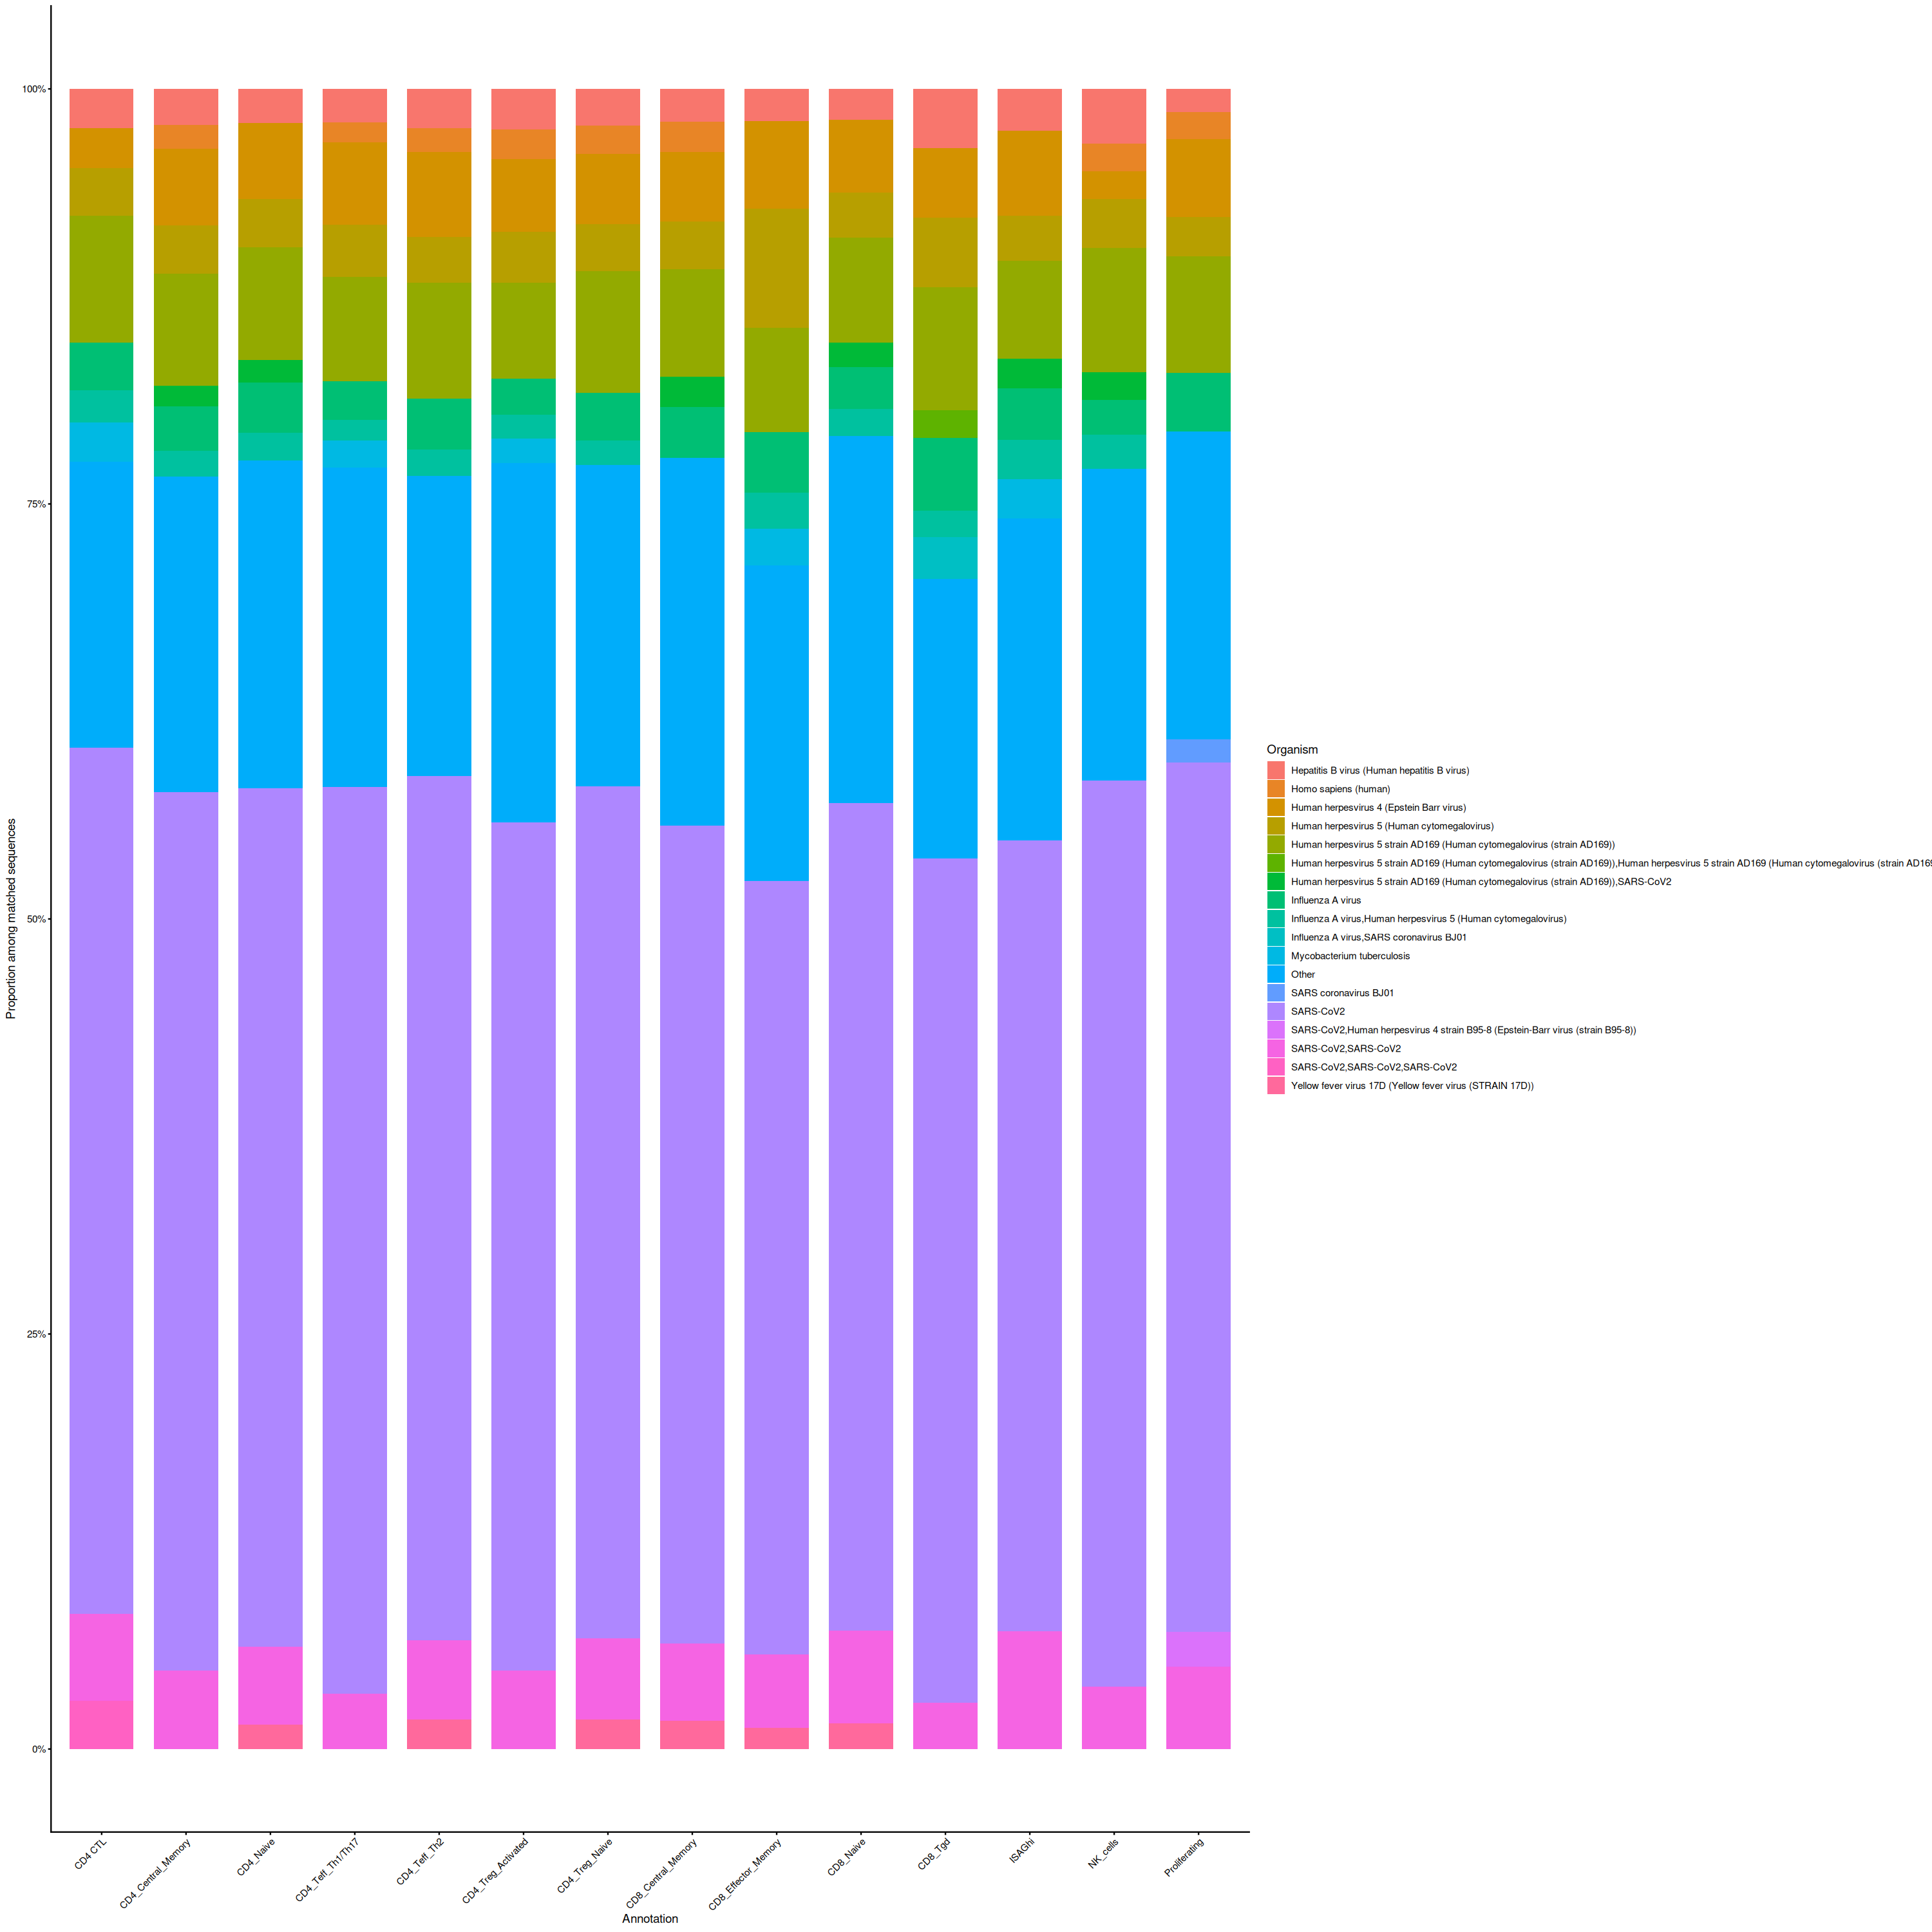

In [51]:
library(dplyr)
library(ggplot2)

plot_df <- md_blood_5p %>%
  filter(!is.na(match_sequence), !is.na(organism)) %>%
  dplyr::count(annot_and_cd4_ctl, organism, name = "n") %>%
  group_by(annot_and_cd4_ctl) %>%
  arrange(desc(n), organism, .by_group = TRUE) %>%
  mutate(
    organism_plot = if_else(
      row_number() <= 10,
      as.character(organism),
      "Other"
    )
  ) %>%
  group_by(annot_and_cd4_ctl, organism_plot) %>%
  summarise(n = sum(n), .groups = "drop") %>%
  group_by(annot_and_cd4_ctl) %>%
  mutate(proportion = n / sum(n)) %>%
  ungroup()

ggplot(
  plot_df,
  aes(x = annot_and_cd4_ctl, y = proportion, fill = organism_plot)
) +
  geom_col(width = 0.75) +
  scale_y_continuous(labels = scales::label_percent()) +
  labs(
    x = "Annotation",
    y = "Proportion among matched sequences",
    fill = "Organism"
  ) +
  theme_classic() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

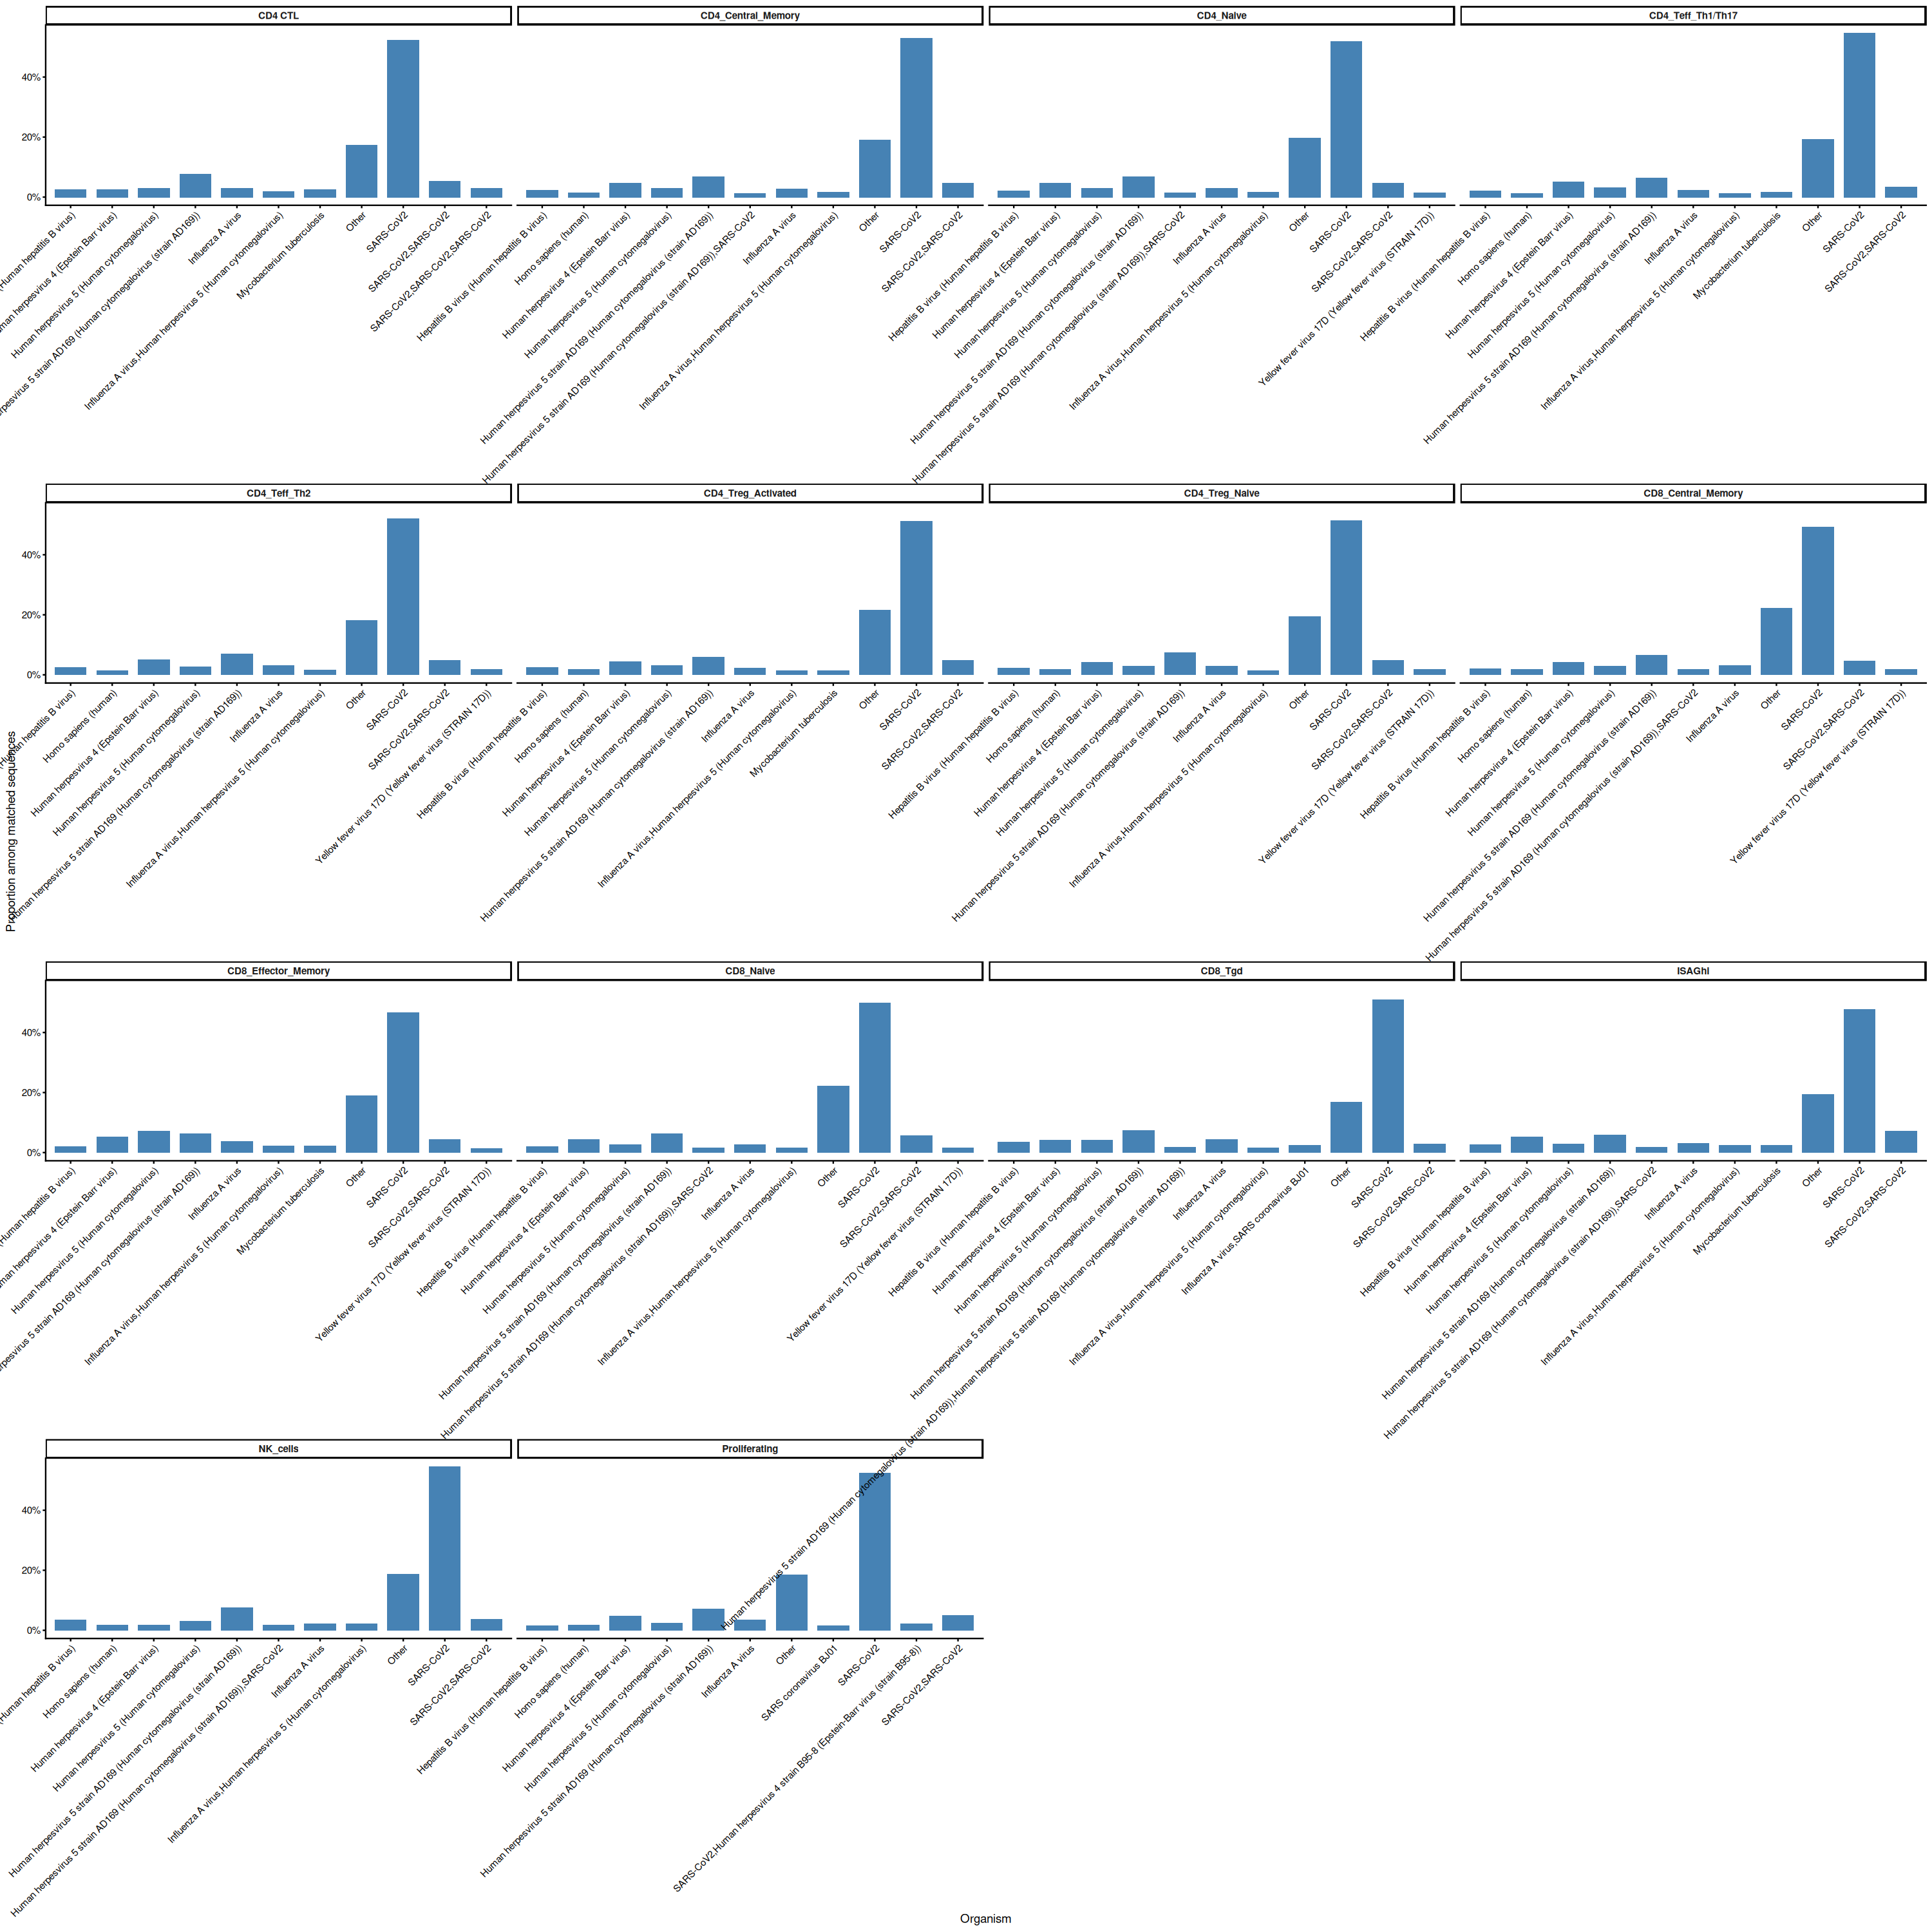

In [49]:
options(repr.plot.width = 25, repr.plot.height = 25)
plot_df <- md_blood_5p %>%
  dplyr::filter(!is.na(match_sequence), !is.na(organism)) %>%
  dplyr::count(annot_and_cd4_ctl, organism, name = "n") %>%
  dplyr::group_by(annot_and_cd4_ctl) %>%
  dplyr::arrange(desc(n), organism, .by_group = TRUE) %>%
  dplyr::mutate(
    organism_plot = if_else(
      row_number() <= 10,
      as.character(organism),
      "Other"
    )
  ) %>%
  dplyr::group_by(annot_and_cd4_ctl, organism_plot) %>%
  dplyr::summarise(n = sum(n), .groups = "drop") %>%
  dplyr::group_by(annot_and_cd4_ctl) %>%
  dplyr::mutate(proportion = n / sum(n)) %>%
  dplyr::ungroup()

ggplot(plot_df, aes(x = organism_plot, y = proportion)) +
  geom_col(fill = "steelblue", width = 0.75) +
  facet_wrap(~ annot_and_cd4_ctl, scales = "free_x") +
  scale_y_continuous(labels = scales::label_percent()) +
  labs(
    x = "Organism",
    y = "Proportion among matched sequences"
  ) +
  theme_classic() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(face = "bold")
  )

In [50]:
md_blood_5p  %>% dplyr::filter(annot_and_cd4_ctl == "CD4 CTL")  %>% 
group_by(organism)  %>% tally()  %>% arrange(desc(n))

organism,n
<chr>,<int>
NA,1407
SARS-CoV2,109
Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169)),16
"SARS-CoV2,SARS-CoV2",11
Human herpesvirus 5 (Human cytomegalovirus),6
Influenza A virus,6
"SARS-CoV2,SARS-CoV2,SARS-CoV2",6
Hepatitis B virus (Human hepatitis B virus),5
Human herpesvirus 4 (Epstein Barr virus),5


In [55]:
library(dplyr)
library(stringr)

# Standardize individual organism names
standardize_organism <- function(x) {

  x <- stringr::str_trim(x)

  dplyr::case_when(
    str_detect(x, regex("SARS[- ]?CoV[- ]?2", ignore_case = TRUE)) ~
      "SARS-CoV-2",

    str_detect(x, regex(
      "SARS[- ]?CoV[- ]?1|SARS coronavirus",
      ignore_case = TRUE
    )) ~ "SARS-CoV-1",

    str_detect(x, regex(
      "human cytomegalovirus|human herpesvirus 5",
      ignore_case = TRUE
    )) ~ "CMV",

    str_detect(x, regex(
      "Epstein.?Barr|human herpesvirus 4",
      ignore_case = TRUE
    )) ~ "EBV",

    str_detect(x, regex("Influenza A|^H1N1 subtype", ignore_case = TRUE)) ~
      "Influenza A",

    str_detect(x, regex("Hepatitis B", ignore_case = TRUE)) ~ "HBV",

    str_detect(x, regex("Hepatitis C", ignore_case = TRUE)) ~ "HCV",

    str_detect(x, regex("Human immunodeficiency virus 1", ignore_case = TRUE)) ~
      "HIV-1",

    str_detect(x, regex("Yellow fever", ignore_case = TRUE)) ~
      "Yellow fever virus",

    str_detect(x, regex(
      "choriomeningitidis|choriomeningitis",
      ignore_case = TRUE
    )) ~ "LCMV",

    str_detect(x, regex("Homo sapiens", ignore_case = TRUE)) ~
      "Human",

    TRUE ~ x
  )
}

# Split each row, standardize labels, and remove repeated organisms
collapse_organisms <- function(x) {

  if (is.na(x) || !nzchar(trimws(x))) {
    return(NA_character_)
  }

  labels <- strsplit(x, split = ",", fixed = TRUE)[[1]]
  labels <- standardize_organism(labels)
  labels <- sort(unique(labels[!is.na(labels) & nzchar(labels)]))

  if (length(labels) == 0L) {
    return(NA_character_)
  }

  paste(labels, collapse = "; ")
}

In [57]:
blood_5p_output_iedb_2 <- blood_5p_output_iedb %>%
  dplyr::mutate(
    # All distinct standardized organisms associated with this row
    organism_groups = vapply(
      as.character(organism),
      collapse_organisms,
      character(1)
    ),

    # Single category per row for plotting
    organism_clean = dplyr::case_when(
      is.na(organism_groups) ~ NA_character_,
      stringr::str_detect(organism_groups, fixed("; ")) ~
        "Multiple organisms",
      TRUE ~ organism_groups
    )
  )

# Check the resulting categories
blood_5p_output_iedb_2 %>%
  dplyr::filter(!is.na(match_sequence)) %>%
  dplyr::count(organism_clean, sort = TRUE)

organism_clean,n
<chr>,<int>
SARS-CoV-2,41173
Multiple organisms,8373
CMV,7198
EBV,4250
Influenza A,3390
NA,1603
HBV,1505
Yellow fever virus,1208
Human,1167


In [60]:
blood_5p_output_iedb_2

trimmed_input_sequence,match_sequence,score,receptor_group,epitope,antigen,organism,organism_groups,organism_clean
<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
ASSLVASGTDTQY,ASSLLASGTDTQY,0.979610,100683,RNPANNAAIVL,nucleocapsid phosphoprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2,SARS-CoV-2,SARS-CoV-2
ASSLVASGTDTQY,ASSLVATGTDTQY,0.978249,103214,MIELSLIDFYLCFLAFLLFLVLIML,ORF7b [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2,SARS-CoV-2,SARS-CoV-2
ASSPGLAGLTDTQY,ASSPGLAGLTDTQY,1.000000,10589,NLVPMVATV,HCMVUL83,Human herpesvirus 5 (Human cytomegalovirus),CMV,CMV
ASSYSDSNQPQH,ASSYSDSNQPQH,1.000000,48476,KLGGALQAK,55 kDa immediate-early protein 1,Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169)),CMV,CMV
ASSPTGGYEQY,ASSPTGGYEQY,1.000000,115550,"KAVYNFATC,IMLIIFWFSL","Pre-glycoprotein polyprotein GP complex,ORF7b [Severe acute respiratory syndrome coronavirus 2]","Mammarenavirus choriomeningitidis (Lymphocytic choriomeningitis mammarenavirus),SARS-CoV2",LCMV; SARS-CoV-2,Multiple organisms
ASSPTGGYEQY,ASSPSGGYEQY,0.975504,109662,FLWLLWPVTLACFVLAAV,membrane glycoprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2,SARS-CoV-2,SARS-CoV-2
ASSPTGGYEQY,ASSPSGGYEQY,0.975504,203892,NYNYLYRLF,surface glycoprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2,SARS-CoV-2,SARS-CoV-2
ASSPTGGYEQY,ASKPTGGYEQY,0.970456,184092,YLVYQMLKV,NA,NA,NA,NA
ASTLAGETQY,ASSLAGETQY,0.983011,89162,"GLEAPFLYLYALVYFLQSINFVRIIMR,MGYINVFAFPFTIYSL,MIELSLIDFYLCFLAFLLFLVLIML","ORF3a protein [Severe acute respiratory syndrome coronavirus 2],ORF10 protein [Severe acute respiratory syndrome coronavirus 2],ORF7b [Severe acute respiratory syndrome coronavirus 2]","SARS-CoV2,SARS-CoV2,SARS-CoV2",SARS-CoV-2,SARS-CoV-2


In [64]:
matched_df <- md_blood_5p %>%
left_join(blood_5p_output_iedb_2)  %>% 
  dplyr::filter(
    !is.na(match_sequence),
    !is.na(organism_clean)
  )

Joining with `by = join_by(trimmed_input_sequence, match_sequence, score,
receptor_group, epitope, antigen, organism)`


In [65]:
# Top 5 corrected organism labels across all clusters
top5 <- matched_df %>%
  dplyr::count(organism_clean, sort = TRUE) %>%
  dplyr::filter(organism_clean != "Other") %>%
  dplyr::slice_head(n = 5) %>%
  dplyr::pull(organism_clean)

plot_df <- matched_df %>%
  dplyr::mutate(
    organism_plot = if_else(
      organism_clean %in% top5,
      as.character(organism_clean),
      "Other"
    )
  ) %>%
  dplyr::count(annot_and_cd4_ctl, organism_plot, name = "n") %>%
  dplyr::group_by(annot_and_cd4_ctl) %>%
  dplyr::mutate(proportion = n / sum(n)) %>%
  dplyr::ungroup() %>%
  dplyr::mutate(
    organism_plot = factor(
      organism_plot,
      levels = c(top5, "Other")
    )
  )

In [87]:
# Tableau 10 palette
tableau10 <- c(
  "#4E79A7", "#F28E2B", "#E15759", "#76B7B2", "#59A14F",
  "#EDC948", "#B07AA1", "#FF9DA7", "#9C755F", "#BAB0AC"
)

organism_colors <- c(
  setNames(tableau10[seq_along(top5)], top5),
  "Other" = "grey80"
)

In [89]:
organism_colors

SARS-CoV-2 Multiple organisms                CMV                EBV 
         "#4E79A7"          "#F28E2B"          "#E15759"          "#76B7B2" 
       Influenza A              Other 
         "#59A14F"           "grey80"

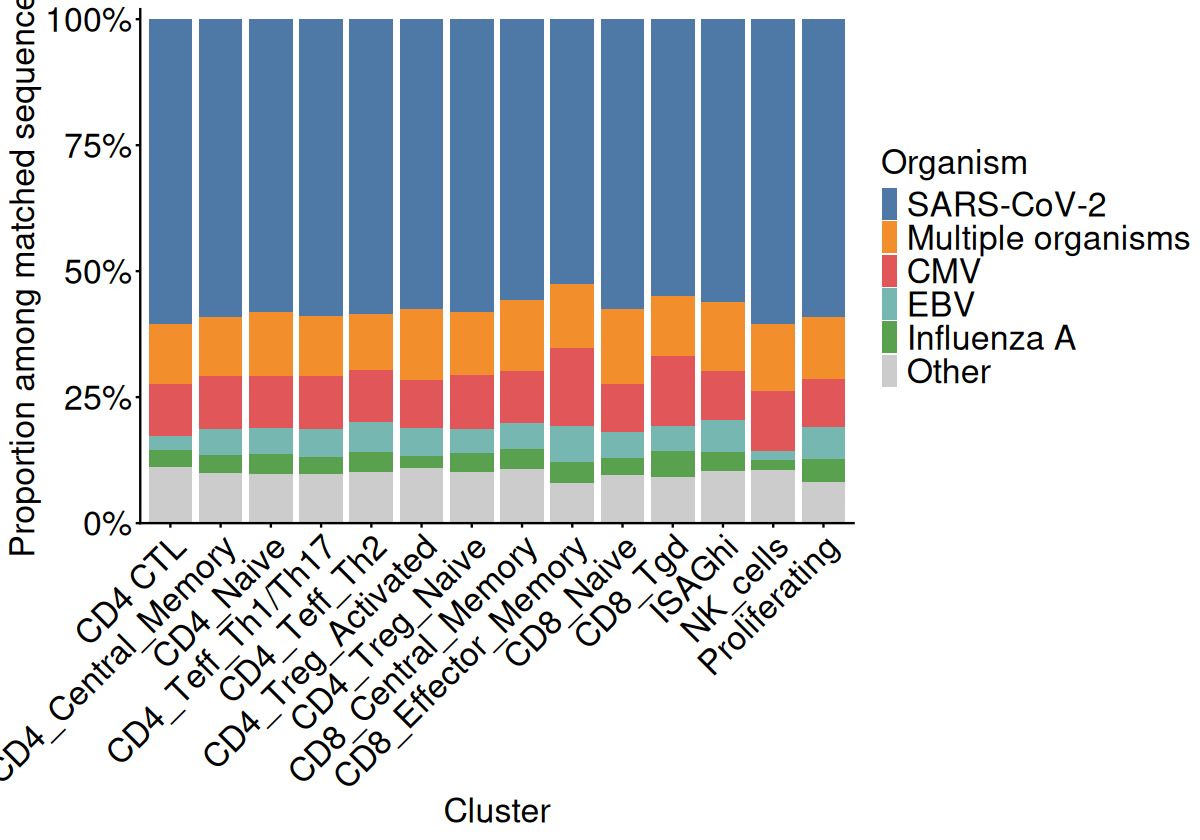

In [96]:
options(repr.plot.width = 10, repr.plot.height = 7)
ggplot(
  plot_df,
  aes(x = annot_and_cd4_ctl, y = proportion, fill = organism_plot)
) +
  geom_col(width = 0.85) +
  scale_fill_manual(values = organism_colors, drop = FALSE) +
  scale_y_continuous(
    labels = scales::label_percent(),
    expand = expansion(mult = c(0, 0.02))
  ) +
  labs(
    x = "Cluster",
    y = "Proportion among matched sequences",
    fill = "Organism"
  ) +
  theme_classic() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1)
  ) + ggtheme()

In [97]:
ggsave(filename = "figures/blood_tcrmatch_iedb1.svg",
                  width = 25, height = 20, units = "cm")

In [ ]:
organisms_use <- c("SARS-CoV-2", "Influenza A", "EBV", "CMV", "Human")

matched_df <- md_blood_5p %>%
left_join(blood_5p_output_iedb_2)  %>% 
  dplyr::filter(
    !is.na(participant_id),
    !is.na(annot_and_cd4_ctl),
    !is.na(match_sequence),
    !is.na(organism_clean)
  )

# Denominator: all matched, organism-annotated rows per donor × annotation
donor_totals <- matched_df %>%
  dplyr::count(participant_id, annot_and_cd4_ctl, name = "n_total")

# Numerator: hits for each selected organism
organism_counts <- matched_df %>%
  dplyr::filter(organism_clean %in% organisms_use) %>%
  dplyr::count(
    participant_id, annot_and_cd4_ctl, organism_clean,
    name = "n_hits"
  )

# Include zero frequencies for organisms absent from a donor × annotation
freq_df <- tidyr::expand_grid(
  donor_totals,
  organism_clean = organisms_use
) %>%
  dplyr::left_join(
    organism_counts,
    by = c("participant_id", "annot_and_cd4_ctl", "organism_clean")
  ) %>%
  dplyr::mutate(
    n_hits = tidyr::replace_na(n_hits, 0L),
    frequency = n_hits / n_total,
    organism_clean = factor(organism_clean, levels = organisms_use)
  )

In [92]:
organism_colors["Human"]     <- "#EDC948"

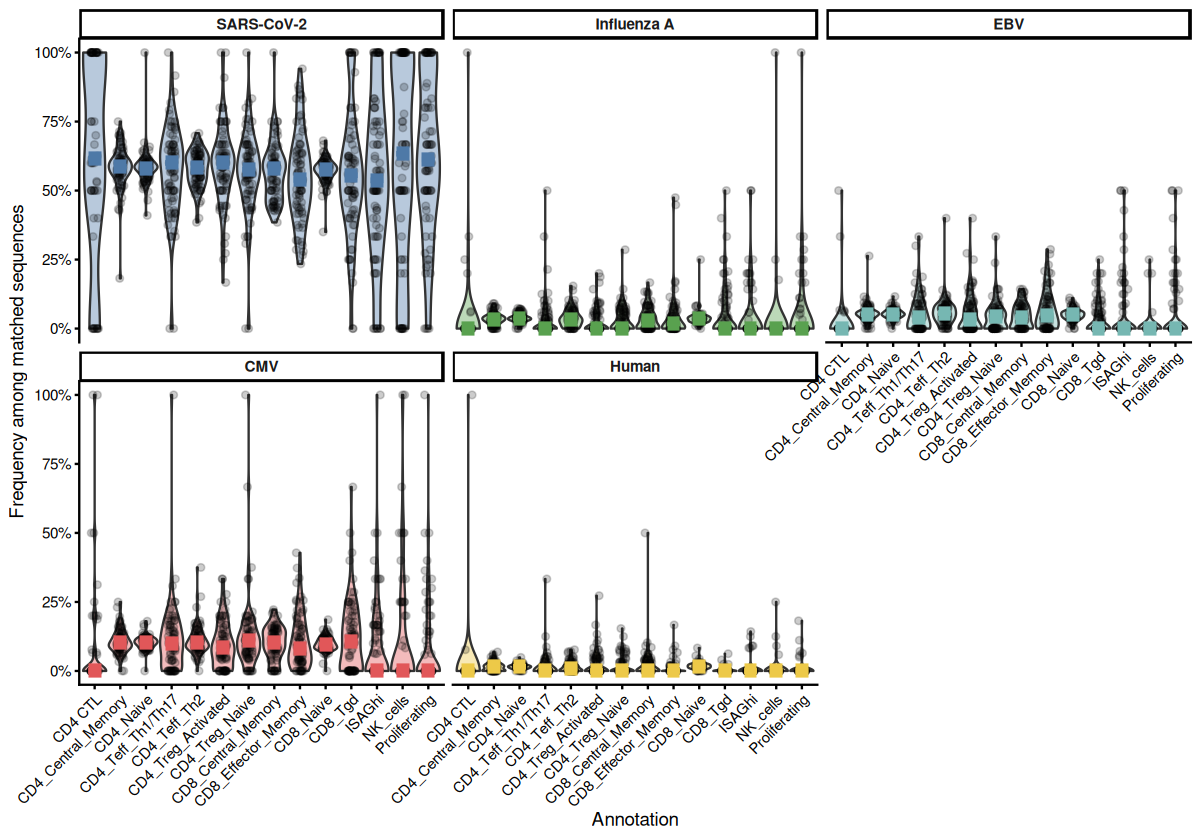

In [93]:
options(repr.plot.width = 10, repr.plot.height = 7)
ggplot(
  freq_df,
  aes(
    x = annot_and_cd4_ctl,
    y = frequency,
    fill = organism_clean
  )
) +
  geom_violin(
    scale = "width",
    alpha = 0.4
  ) +
  geom_point(
    position = position_jitter(width = 0.15, height = 0, seed = 1),
    size = 1.5,
    alpha = 0.2
  ) +
  stat_summary(
    fun = median,
    fun.min = median,
    fun.max = median,
    geom = "crossbar",
    width = 0.5,
    linewidth = 1.2,
    aes(colour = organism_clean)
  ) +
  facet_wrap(~ organism_clean, ncol = 3) +
  scale_fill_manual(values = organism_colors) +
  scale_color_manual(values = organism_colors) +
  scale_y_continuous(labels = scales::label_percent()) +
  labs(
    x = "Annotation",
    y = "Frequency among matched sequences"
  ) +
  theme_classic() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(face = "bold"),
    legend.position = "none"
  ) 

In [95]:
ggsave(filename = "figures/blood_tcrmatch_iedb2.svg",
                  width = 23, height = 15, units = "cm")

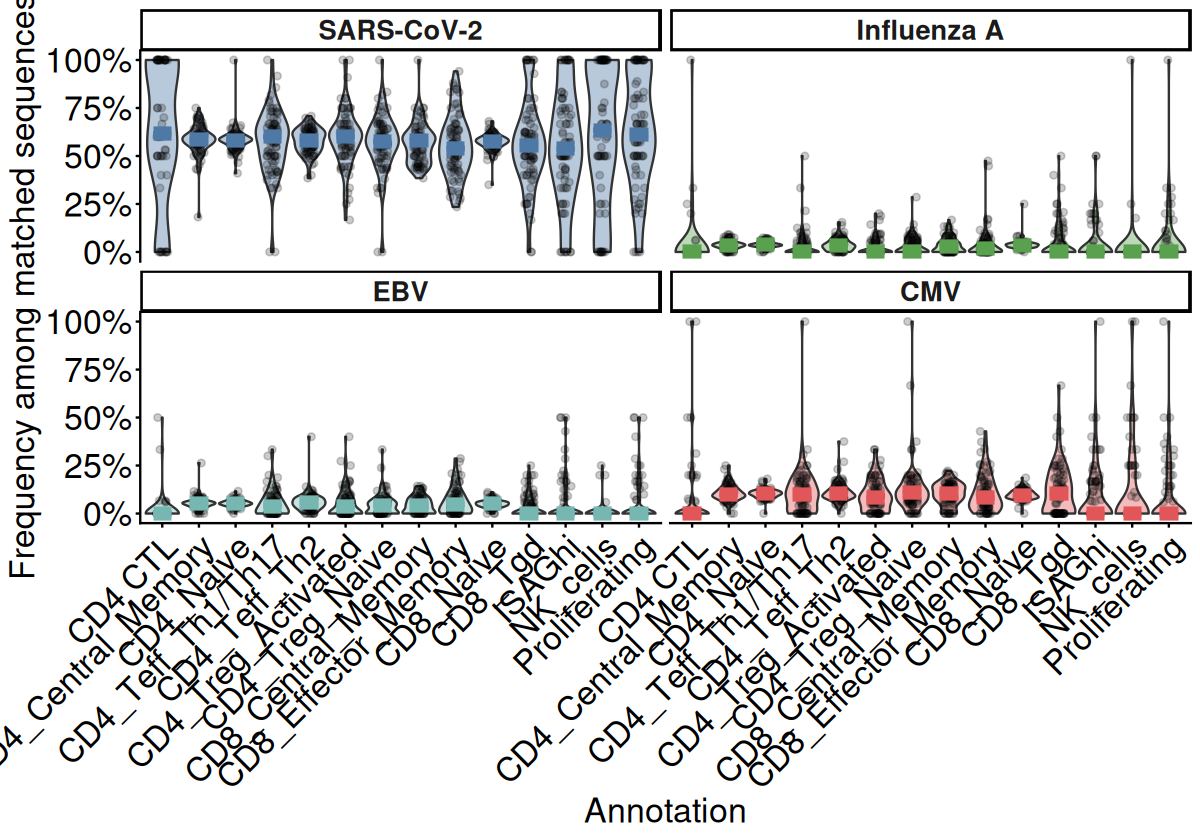

In [104]:
options(repr.plot.width = 10, repr.plot.height = 7)
ggplot(
  freq_df  %>% dplyr::filter(organism_clean != "Human"),
  aes(
    x = annot_and_cd4_ctl,
    y = frequency,
    fill = organism_clean
  )
) +
  geom_violin(
    scale = "width",
    alpha = 0.4
  ) +
  geom_point(
    position = position_jitter(width = 0.15, height = 0, seed = 1),
    size = 1.5,
    alpha = 0.2
  ) +
  stat_summary(
    fun = median,
    fun.min = median,
    fun.max = median,
    geom = "crossbar",
    width = 0.5,
    linewidth = 1.2,
    aes(colour = organism_clean)
  ) +
  facet_wrap(~ organism_clean, ncol = 2) +
  scale_fill_manual(values = organism_colors) +
  scale_color_manual(values = organism_colors) +
  scale_y_continuous(labels = scales::label_percent()) +
  labs(
    x = "Annotation",
    y = "Frequency among matched sequences"
  ) +
  theme_classic() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(face = "bold"),
    legend.position = "none"
  ) + ggtheme()

In [106]:
ggsave(filename = "figures/blood_tcrmatch_iedb3.svg",
                  width = 22, height = 30, units = "cm")

## Only 100% matches

In [42]:
rownames(md_blood_5p)  <- colnames(seu)

In [43]:
md_blood_5p

,orig.ident,nCount_RNA,nFeature_RNA,sample,CTgene,CTnt,CTaa,CTstrict,clonalProportion,clonalFrequency,⋯,clone_aa,sample_number,condition,trimmed_input_sequence,match_sequence,score,receptor_group,epitope,antigen,organism
,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
FPIES_1-GENE_AAACCTGAGAGCAATT-1,SeuratProject,2520,978,1-GENE,TRAV17.TRAJ47.TRAC_TRBV7-2.NA.TRBJ2-2.TRBC2,TGTGCTACGGACTCGGGAGGAAACAAACTGGTCTTT_TGTGCCAGCAGCTTAGTTTCTAACACCGGGGAGCTGTTTTTT,CATDSGGNKLVF_CASSLVSNTGELFF,TRAV17.TRAJ47.TRAC;TGTGCTACGGACTCGGGAGGAAACAAACTGGTCTTT_TRBV7-2.NA.TRBJ2-2.TRBC2;TGTGCCAGCAGCTTAGTTTCTAACACCGGGGAGCTGTTTTTT,0.0001545117,1,⋯,CDR3b CASSLVSNTGELFF CDR3a CATDSGGNKLVF,1,FPIES_active,ASSLVSNTGELF,ASSLASNTGELF,0.97238,204028,NYNYLYRLF,surface glycoprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
FPIES_1-GENE_AAACCTGAGAGGTACC-1,SeuratProject,3623,1311,1-GENE,TRAV26-1.TRAJ6.TRAC_TRBV27.NA.TRBJ1-2.TRBC1,TGCATCGTCAGAGTCCCGTCATCAGGAGGAAGCTACATACCTACATTT_TGTGCCAGCAGTTTAGCGCAGGGAGGGAGCTATGGCTACACCTTC,CIVRVPSSGGSYIPTF_CASSLAQGGSYGYTF,TRAV26-1.TRAJ6.TRAC;TGCATCGTCAGAGTCCCGTCATCAGGAGGAAGCTACATACCTACATTT_TRBV27.NA.TRBJ1-2.TRBC1;TGTGCCAGCAGTTTAGCGCAGGGAGGGAGCTATGGCTACACCTTC,0.0001545117,1,⋯,CDR3b CASSLAQGGSYGYTF CDR3a CIVRVPSSGGSYIPTF,1,FPIES_active,ASSLAQGGSYGYT,NA,NA,NA,NA,NA,NA
FPIES_1-GENE_AAACCTGAGATCTGCT-1,SeuratProject,2847,1092,1-GENE,TRAV5.TRAJ37.TRAC;TRAV21.TRAJ24.TRAC_TRBV29-1.NA.TRBJ1-3.TRBC1,TGTGCAGAGAGCCATGGCTCTAGCAACACAGGCAAACTAATCTTT;TGTGCTGTTATGACAACTGACAGCTGGGGGAAATTGCAGTTT_TGCAGCGTTGCGGAGGGAAACACCATATATTTT,CAESHGSSNTGKLIF;CAVMTTDSWGKLQF_CSVAEGNTIYF,TRAV5.TRAJ37.TRAC;TRAV21.TRAJ24.TRAC;TGTGCAGAGAGCCATGGCTCTAGCAACACAGGCAAACTAATCTTT;TGTGCTGTTATGACAACTGACAGCTGGGGGAAATTGCAGTTT_TRBV29-1.NA.TRBJ1-3.TRBC1;TGCAGCGTTGCGGAGGGAAACACCATATATTTT,0.0001545117,1,⋯,CDR3b CSVAEGNTIYF CDR3a CAVMTTDSWGKLQF,1,FPIES_active,SVAEGNTIY,NA,NA,NA,NA,NA,NA
FPIES_1-GENE_AAACCTGAGTGCGTGA-1,SeuratProject,2329,928,1-GENE,TRAV23/DV6.TRAJ22.TRAC_TRBV28.NA.TRBJ1-1.TRBC1,TGTGCAGCAAGCGGGTATTATCTGTCCGGTTCTGCAAGGCAACTGACCTTT_TGTGCCAGCAGTTTAGGGGCCGTAGGGACAGTTGGTAAGGCTTTCTTT,CAASGYYLSGSARQLTF_CASSLGAVGTVGKAFF,TRAV23/DV6.TRAJ22.TRAC;TGTGCAGCAAGCGGGTATTATCTGTCCGGTTCTGCAAGGCAACTGACCTTT_TRBV28.NA.TRBJ1-1.TRBC1;TGTGCCAGCAGTTTAGGGGCCGTAGGGACAGTTGGTAAGGCTTTCTTT,0.0001545117,1,⋯,CDR3b CASSLGAVGTVGKAFF CDR3a CAASGYYLSGSARQLTF,1,FPIES_active,ASSLGAVGTVGKAF,NA,NA,NA,NA,NA,NA
FPIES_1-GENE_AAACCTGAGTGTACCT-1,SeuratProject,1924,868,1-GENE,NA_TRBV18.NA.TRBJ1-5.TRBC1,NA_TGTGCCAGCTCACCCAAATCTTACCTCAGGGGGCATCAGCCCCAGCATTTT,NA_CASSPKSYLRGHQPQHF,NA;NA_TRBV18.NA.TRBJ1-5.TRBC1;TGTGCCAGCTCACCCAAATCTTACCTCAGGGGGCATCAGCCCCAGCATTTT,0.0001545117,1,⋯,CDR3b CASSPKSYLRGHQPQHF CDR3a NA,1,FPIES_active,ASSPKSYLRGHQPQH,NA,NA,NA,NA,NA,NA
FPIES_1-GENE_AAACCTGCAAATTGCC-1,SeuratProject,2840,1084,1-GENE,NA_TRBV12-3.NA.TRBJ2-5.TRBC2,NA_TGTGCCAGCAGAATGACAGGGGAAGAGACCCAGTACTTC,NA_CASRMTGEETQYF,NA;NA_TRBV12-3.NA.TRBJ2-5.TRBC2;TGTGCCAGCAGAATGACAGGGGAAGAGACCCAGTACTTC,0.0001545117,1,⋯,CDR3b CASRMTGEETQYF CDR3a NA,1,FPIES_active,ASRMTGEETQY,NA,NA,NA,NA,NA,NA
FPIES_1-GENE_AAACCTGCACCTCGGA-1,SeuratProject,3934,1381,1-GENE,TRAV10.TRAJ18.TRAC_TRBV4-1.NA.TRBJ2-5.TRBC2;TRBV6-5.NA.TRBJ2-1.TRBC2,TGTGTGGTGAGCGCCGGCAGAGGCTCAACCCTGGGGAGGCTATACTTT_TGCGCCAGCAGCCAAGCCCCCACCGAGACCCAGTACTTC;TGTGCCAGCCAGCCCCCCGGGGGCTATGAGCAGTTCTTC,CVVSAGRGSTLGRLYF_CASSQAPTETQYF;CASQPPGGYEQFF,TRAV10.TRAJ18.TRAC;TGTGTGGTGAGCGCCGGCAGAGGCTCAACCCTGGGGAGGCTATACTTT_TRBV4-1.NA.TRBJ2-5.TRBC2;TRBV6-5.NA.TRBJ2-1.TRBC2;TGCGCCAGCAGCCAAGCCCCCACCGAGACCCAGTACTTC;TGTGCCAGCCAGCCCCCCGGGGGCTATGAGCAGTTCTTC,0.0001545117,1,⋯,CDR3b CASSQAPTETQYF CDR3a CVVSAGRGSTLGRLYF,1,FPIES_active,ASSQAPTETQY,NA,NA,NA,NA,NA,NA
FPIES_1-GENE_AAACCTGGTAGCGATG-1,SeuratProject,1619,658,1-GENE,NA_TRBV27.NA.TRBJ1-6.TRBC1,NA_TGTGCCAGCAGTTTTCGCAGGGGGGGGAATTCACCCCTCCACTTT,NA_CASSFRRGGNSPLHF,NA;NA_TRBV27.NA.TRBJ1-6.TRBC1;TGTGCCAGCAGTTTTCGCAGGGGGGGGAATTCACCCCTCCACTTT,0.0001545117,1,⋯,CDR3b CASSFRRGGNSPLHF CDR3a N

In [44]:
seu@meta.data  <- md_blood_5p

In [45]:
seu@meta.data  <- seu@meta.data  %>% separate(organism, into = c("organism2", NA, NA), sep = "\\(", remove = F)

Warning message:
“Expected 3 pieces. Additional pieces discarded in 662 rows [229, 323, 339, 872,
878, 900, 1609, 1719, 1791, 1919, 1924, 2358, 2629, 2658, 2966, 2976, 2989,
3334, 4403, 4423, ...].”
Warning message:
“Expected 3 pieces. Missing pieces filled with `NA` in 10199 rows [1, 47, 67,
68, 69, 71, 78, 89, 102, 122, 129, 139, 149, 152, 162, 181, 193, 198, 239, 247,
...].”


In [46]:
seu@meta.data  <- seu@meta.data  %>% separate(organism2, into = c("organism2", NA, NA), sep = "\\,", remove = F)

Warning message:
“Expected 3 pieces. Additional pieces discarded in 125 rows [3163, 4877, 5543,
7489, 7733, 14455, 18072, 18169, 18595, 19582, 20977, 23273, 24379, 24778,
26323, 26970, 27802, 29574, 30515, 30531, ...].”
Warning message:
“Expected 3 pieces. Missing pieces filled with `NA` in 12222 rows [1, 47, 67,
68, 69, 70, 78, 86, 89, 102, 122, 127, 129, 139, 149, 152, 162, 181, 193, 198,
...].”


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



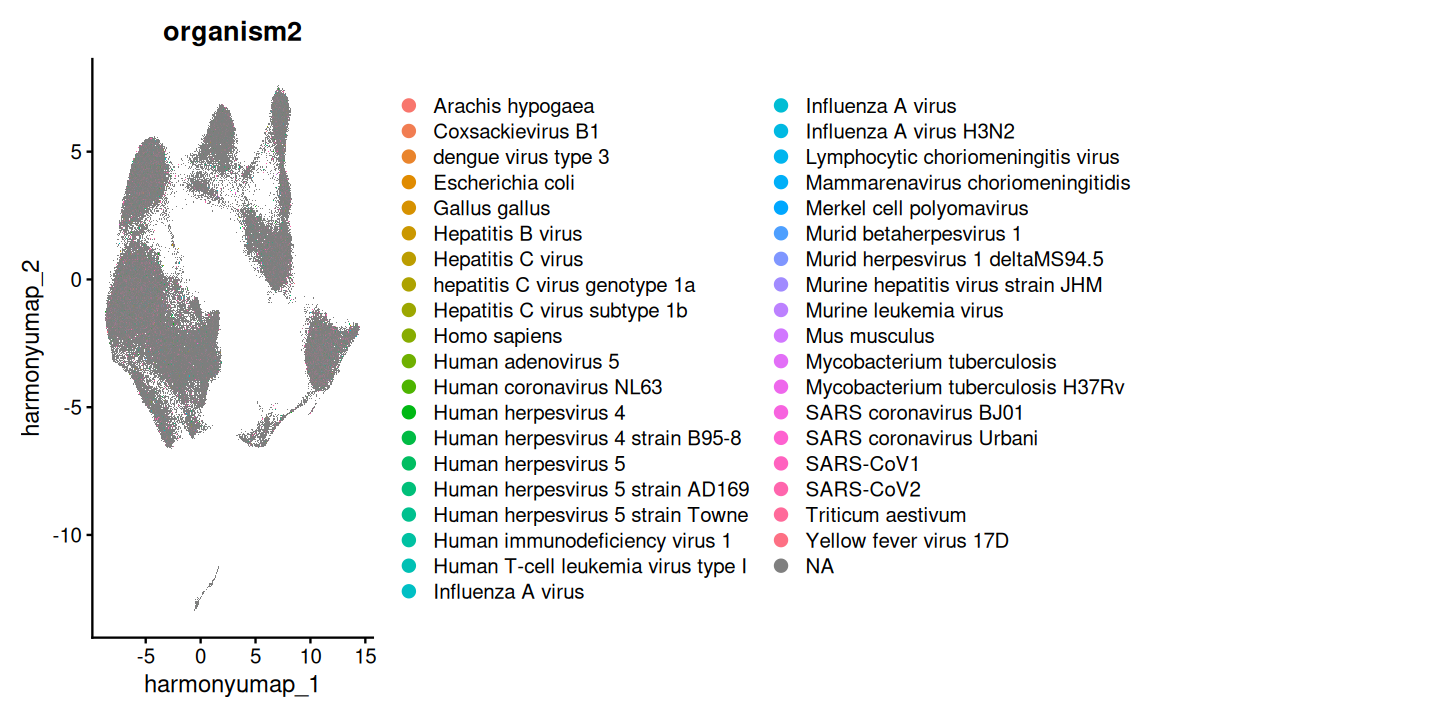

In [47]:
options(repr.plot.width = 12, repr.plot.height = 6)
DimPlot(seu, group.by = "organism2", ncol = 2, reduction = "harmony_umap")

In [ ]:
# Step 1 - save amino acid sequences of TCRb to a txt file

In [25]:
seu$cdr3_B  %>% head

FPIES_1-GENE_AAACCTGAGAGCAATT-1 FPIES_1-GENE_AAACCTGAGAGGTACC-1 
               "CASSLVSNTGELFF"               "CASSLAQGGSYGYTF" 
FPIES_1-GENE_AAACCTGAGATCTGCT-1 FPIES_1-GENE_AAACCTGAGTGCGTGA-1 
                  "CSVAEGNTIYF"              "CASSLGAVGTVGKAFF" 
FPIES_1-GENE_AAACCTGAGTGTACCT-1 FPIES_1-GENE_AAACCTGCAAATTGCC-1 
            "CASSPKSYLRGHQPQHF"                 "CASRMTGEETQYF"

In [26]:
tcrb2 <- as.data.frame(unique(seu$cdr3_B))  

colnames(tcrb2) = "seq"

tcrb2  <-  tcrb2 %>% dplyr::filter(seq != "NA")

write_delim(tcrb2, delim = "\t", quote = "none", col_names = F, 
            file = "../241201_VN_PREDICT2/data/unrelated/tcrb_blood_5p.csv")

In [27]:
tcrb2

seq
<chr>
CASSLVSNTGELFF
CASSLAQGGSYGYTF
CSVAEGNTIYF
CASSLGAVGTVGKAFF
CASSPKSYLRGHQPQHF
CASRMTGEETQYF
CASSQAPTETQYF
CASSFRRGGNSPLHF
CAWRGVQETQYF


In [ ]:
# Step 2 - run the TCRMatch algorithm


This code should be run in bash:

`./tcrmatch -i ./input/tcrb_blood_5p.txt -t 12 -d ./data/IEDB_data.tsv  > ./output/blood_5p_output_iedb.tsv`

`./tcrmatch -i ./input/tcrb_blood_5p.txt -t 12 -d ./data/CEDAR_data.tsv  > ./output/blood_5p_output_cedar.tsv`


In [ ]:
# Step 3 - load the outputs

In [28]:
blood_5p_output_iedb  <- read_delim("data/unrelated/tcrmatch/blood_5p_output_iedb.tsv", delim = "\t")

Rows: 11170 Columns: 7
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (5): trimmed_input_sequence, match_sequence, epitope, antigen, organism
dbl (2): score, receptor_group

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [29]:
seu$cdr3_B %in% blood_5p_output_iedb$trimmed_input_sequence  %>% table

.
 FALSE 
241759 

In [30]:
## Need to trim cdr3_b sequence

In [31]:
seu$trimmed_input_sequence  <- substr(seu$cdr3_B,2,nchar(seu$cdr3_B)-1)

In [32]:
seu$trimmed_input_sequence %in% blood_5p_output_iedb$trimmed_input_sequence  %>% table

.
 FALSE   TRUE 
228814  12945 

In [33]:
md_blood_5p  <- seu@meta.data  %>% left_join(blood_5p_output_iedb)

Joining with `by = join_by(trimmed_input_sequence)`
Warning message in left_join(., fpies_output_iedb):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 46 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


Need to correct that some sequences are duplicated. 

In [34]:
blood_5p_output_iedb$trimmed_input_sequence  %>% duplicated  %>% table

.
FALSE  TRUE 
 5460  5710 

In [35]:
just_organism  <- blood_5p_output_iedb  %>% dplyr::select(trimmed_input_sequence, organism)  %>% unique

In [36]:
just_organism$trimmed_input_sequence  %>% duplicated  %>% table

.
FALSE  TRUE 
 5460  3661 

3661 sequences are specific to multiple organisms

Let's filter the hits with the highest score for those. 

In [37]:
blood_5p_output_iedb_noDupl  <- blood_5p_output_iedb  %>% group_by(trimmed_input_sequence)  %>% 
slice_max(order_by = score, n = 1, with_ties = F)

In [38]:
blood_5p_output_iedb_noDupl$trimmed_input_sequence  %>% duplicated  %>% table

.
FALSE 
 5460 

In [39]:
blood_5p_output_iedb_noDupl

trimmed_input_sequence,match_sequence,score,receptor_group,epitope,antigen,organism
<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
AAGEQY,ASGEQY,0.979754,18851,ASNENMETM,Nucleoprotein,Influenza A virus (A/Puerto Rico/8/1934(H1N1)) (Influenza A virus (A/PR 8/34 (H1N1)))
AAGLAGNEQF,SAGLAGNEQF,0.992492,143101,MIELSLIDFYLCFLAFLLFLVLIML,ORF7b [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AAGQPQH,SAGQPQH,0.989309,177331,"LSPRWYFYYL,YVLDHLIVV","nucleocapsid phosphoprotein [Severe acute respiratory syndrome coronavirus 2],Replication and transcription activator","SARS-CoV2,Human herpesvirus 4 (Epstein Barr virus)"
AGGGSSYNEQF,GAGGSSYNEQF,0.977592,143404,FVDGVPFVV,orf1ab polyprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AGGPGNTIY,ASGPGNTIY,0.971876,70577,FPPTSFGPL,orf1ab polyprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AGGQGDTEAF,SAGQGDTEAF,0.972957,56195,"KLGGALQAK,AYAQKIFKI","55 kDa immediate-early protein 1,55 kDa immediate-early protein 1","Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169)),Human herpesvirus 5 strain AD169 (Human cytomegalovirus (strain AD169))"
AGGQGYGYT,ASGQGYGYT,0.973540,179790,FQPQNGQFI,Nucleoprotein,Mammarenavirus choriomeningitidis (Lymphocytic choriomeningitis mammarenavirus)
AGGTGGTEAF,ASGTGGTEAF,0.977578,147441,MIELSLIDFYLCFLAFLLFLVLIML,ORF7b [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
AIDRNTEAF,SVDRNTEAF,0.984686,145927,"MMISAGFSL,FVCNLLLLFVTVYSHLLLV","orf1ab polyprotein [Severe acute respiratory syndrome coronavirus 2],ORF3a protein [Severe acute respiratory syndrome coronavirus 2]","SARS-CoV2,SARS-CoV2"


In [40]:
md_blood_5p  <- seu@meta.data  %>% left_join(blood_5p_output_iedb_noDupl)

Joining with `by = join_by(trimmed_input_sequence)`


In [41]:
md_blood_5p

orig.ident,nCount_RNA,nFeature_RNA,sample,CTgene,CTnt,CTaa,CTstrict,clonalProportion,clonalFrequency,⋯,clone_aa,sample_number,condition,trimmed_input_sequence,match_sequence,score,receptor_group,epitope,antigen,organism
<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
SeuratProject,2520,978,1-GENE,TRAV17.TRAJ47.TRAC_TRBV7-2.NA.TRBJ2-2.TRBC2,TGTGCTACGGACTCGGGAGGAAACAAACTGGTCTTT_TGTGCCAGCAGCTTAGTTTCTAACACCGGGGAGCTGTTTTTT,CATDSGGNKLVF_CASSLVSNTGELFF,TRAV17.TRAJ47.TRAC;TGTGCTACGGACTCGGGAGGAAACAAACTGGTCTTT_TRBV7-2.NA.TRBJ2-2.TRBC2;TGTGCCAGCAGCTTAGTTTCTAACACCGGGGAGCTGTTTTTT,0.0001545117,1,⋯,CDR3b CASSLVSNTGELFF CDR3a CATDSGGNKLVF,1,FPIES_active,ASSLVSNTGELF,ASSLASNTGELF,0.97238,204028,NYNYLYRLF,surface glycoprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
SeuratProject,3623,1311,1-GENE,TRAV26-1.TRAJ6.TRAC_TRBV27.NA.TRBJ1-2.TRBC1,TGCATCGTCAGAGTCCCGTCATCAGGAGGAAGCTACATACCTACATTT_TGTGCCAGCAGTTTAGCGCAGGGAGGGAGCTATGGCTACACCTTC,CIVRVPSSGGSYIPTF_CASSLAQGGSYGYTF,TRAV26-1.TRAJ6.TRAC;TGCATCGTCAGAGTCCCGTCATCAGGAGGAAGCTACATACCTACATTT_TRBV27.NA.TRBJ1-2.TRBC1;TGTGCCAGCAGTTTAGCGCAGGGAGGGAGCTATGGCTACACCTTC,0.0001545117,1,⋯,CDR3b CASSLAQGGSYGYTF CDR3a CIVRVPSSGGSYIPTF,1,FPIES_active,ASSLAQGGSYGYT,NA,NA,NA,NA,NA,NA
SeuratProject,2847,1092,1-GENE,TRAV5.TRAJ37.TRAC;TRAV21.TRAJ24.TRAC_TRBV29-1.NA.TRBJ1-3.TRBC1,TGTGCAGAGAGCCATGGCTCTAGCAACACAGGCAAACTAATCTTT;TGTGCTGTTATGACAACTGACAGCTGGGGGAAATTGCAGTTT_TGCAGCGTTGCGGAGGGAAACACCATATATTTT,CAESHGSSNTGKLIF;CAVMTTDSWGKLQF_CSVAEGNTIYF,TRAV5.TRAJ37.TRAC;TRAV21.TRAJ24.TRAC;TGTGCAGAGAGCCATGGCTCTAGCAACACAGGCAAACTAATCTTT;TGTGCTGTTATGACAACTGACAGCTGGGGGAAATTGCAGTTT_TRBV29-1.NA.TRBJ1-3.TRBC1;TGCAGCGTTGCGGAGGGAAACACCATATATTTT,0.0001545117,1,⋯,CDR3b CSVAEGNTIYF CDR3a CAVMTTDSWGKLQF,1,FPIES_active,SVAEGNTIY,NA,NA,NA,NA,NA,NA
SeuratProject,2329,928,1-GENE,TRAV23/DV6.TRAJ22.TRAC_TRBV28.NA.TRBJ1-1.TRBC1,TGTGCAGCAAGCGGGTATTATCTGTCCGGTTCTGCAAGGCAACTGACCTTT_TGTGCCAGCAGTTTAGGGGCCGTAGGGACAGTTGGTAAGGCTTTCTTT,CAASGYYLSGSARQLTF_CASSLGAVGTVGKAFF,TRAV23/DV6.TRAJ22.TRAC;TGTGCAGCAAGCGGGTATTATCTGTCCGGTTCTGCAAGGCAACTGACCTTT_TRBV28.NA.TRBJ1-1.TRBC1;TGTGCCAGCAGTTTAGGGGCCGTAGGGACAGTTGGTAAGGCTTTCTTT,0.0001545117,1,⋯,CDR3b CASSLGAVGTVGKAFF CDR3a CAASGYYLSGSARQLTF,1,FPIES_active,ASSLGAVGTVGKAF,NA,NA,NA,NA,NA,NA
SeuratProject,1924,868,1-GENE,NA_TRBV18.NA.TRBJ1-5.TRBC1,NA_TGTGCCAGCTCACCCAAATCTTACCTCAGGGGGCATCAGCCCCAGCATTTT,NA_CASSPKSYLRGHQPQHF,NA;NA_TRBV18.NA.TRBJ1-5.TRBC1;TGTGCCAGCTCACCCAAATCTTACCTCAGGGGGCATCAGCCCCAGCATTTT,0.0001545117,1,⋯,CDR3b CASSPKSYLRGHQPQHF CDR3a NA,1,FPIES_active,ASSPKSYLRGHQPQH,NA,NA,NA,NA,NA,NA
SeuratProject,2840,1084,1-GENE,NA_TRBV12-3.NA.TRBJ2-5.TRBC2,NA_TGTGCCAGCAGAATGACAGGGGAAGAGACCCAGTACTTC,NA_CASRMTGEETQYF,NA;NA_TRBV12-3.NA.TRBJ2-5.TRBC2;TGTGCCAGCAGAATGACAGGGGAAGAGACCCAGTACTTC,0.0001545117,1,⋯,CDR3b CASRMTGEETQYF CDR3a NA,1,FPIES_active,ASRMTGEETQY,NA,NA,NA,NA,NA,NA
SeuratProject,3934,1381,1-GENE,TRAV10.TRAJ18.TRAC_TRBV4-1.NA.TRBJ2-5.TRBC2;TRBV6-5.NA.TRBJ2-1.TRBC2,TGTGTGGTGAGCGCCGGCAGAGGCTCAACCCTGGGGAGGCTATACTTT_TGCGCCAGCAGCCAAGCCCCCACCGAGACCCAGTACTTC;TGTGCCAGCCAGCCCCCCGGGGGCTATGAGCAGTTCTTC,CVVSAGRGSTLGRLYF_CASSQAPTETQYF;CASQPPGGYEQFF,TRAV10.TRAJ18.TRAC;TGTGTGGTGAGCGCCGGCAGAGGCTCAACCCTGGGGAGGCTATACTTT_TRBV4-1.NA.TRBJ2-5.TRBC2;TRBV6-5.NA.TRBJ2-1.TRBC2;TGCGCCAGCAGCCAAGCCCCCACCGAGACCCAGTACTTC;TGTGCCAGCCAGCCCCCCGGGGGCTATGAGCAGTTCTTC,0.0001545117,1,⋯,CDR3b CASSQAPTETQYF CDR3a CVVSAGRGSTLGRLYF,1,FPIES_active,ASSQAPTETQY,NA,NA,NA,NA,NA,NA
SeuratProject,1619,658,1-GENE,NA_TRBV27.NA.TRBJ1-6.TRBC1,NA_TGTGCCAGCAGTTTTCGCAGGGGGGGGAATTCACCCCTCCACTTT,NA_CASSFRRGGNSPLHF,NA;NA_TRBV27.NA.TRBJ1-6.TRBC1;TGTGCCAGCAGTTTTCGCAGGGGGGGGAATTCACCCCTCCACTTT,0.0001545117,1,⋯,CDR3b CASSFRRGGNSPLHF CDR3a NA,1,FPIES_active,ASSFRRGGNSPLH,NA,NA,NA,NA,NA,NA
SeuratProject,2127,831,1-GENE,TRAV21.TRAJ15.TRAC_TRBV30.NA.TRBJ2-5.TRBC2,TGTGCTGTGACAGATCAGGCAGGAACTGCTCTGATCTTT_TGTGCCTGGAGAGGTGTTCAAGAGACCCAGTACTTC,CAVTDQAGTALIF_CAWRGVQETQYF,TRAV21.TRAJ15.TRAC;TGTGCTGTGACAG

In [42]:
rownames(md_blood_5p)  <- colnames(seu)

In [43]:
md_blood_5p

,orig.ident,nCount_RNA,nFeature_RNA,sample,CTgene,CTnt,CTaa,CTstrict,clonalProportion,clonalFrequency,⋯,clone_aa,sample_number,condition,trimmed_input_sequence,match_sequence,score,receptor_group,epitope,antigen,organism
,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
FPIES_1-GENE_AAACCTGAGAGCAATT-1,SeuratProject,2520,978,1-GENE,TRAV17.TRAJ47.TRAC_TRBV7-2.NA.TRBJ2-2.TRBC2,TGTGCTACGGACTCGGGAGGAAACAAACTGGTCTTT_TGTGCCAGCAGCTTAGTTTCTAACACCGGGGAGCTGTTTTTT,CATDSGGNKLVF_CASSLVSNTGELFF,TRAV17.TRAJ47.TRAC;TGTGCTACGGACTCGGGAGGAAACAAACTGGTCTTT_TRBV7-2.NA.TRBJ2-2.TRBC2;TGTGCCAGCAGCTTAGTTTCTAACACCGGGGAGCTGTTTTTT,0.0001545117,1,⋯,CDR3b CASSLVSNTGELFF CDR3a CATDSGGNKLVF,1,FPIES_active,ASSLVSNTGELF,ASSLASNTGELF,0.97238,204028,NYNYLYRLF,surface glycoprotein [Severe acute respiratory syndrome coronavirus 2],SARS-CoV2
FPIES_1-GENE_AAACCTGAGAGGTACC-1,SeuratProject,3623,1311,1-GENE,TRAV26-1.TRAJ6.TRAC_TRBV27.NA.TRBJ1-2.TRBC1,TGCATCGTCAGAGTCCCGTCATCAGGAGGAAGCTACATACCTACATTT_TGTGCCAGCAGTTTAGCGCAGGGAGGGAGCTATGGCTACACCTTC,CIVRVPSSGGSYIPTF_CASSLAQGGSYGYTF,TRAV26-1.TRAJ6.TRAC;TGCATCGTCAGAGTCCCGTCATCAGGAGGAAGCTACATACCTACATTT_TRBV27.NA.TRBJ1-2.TRBC1;TGTGCCAGCAGTTTAGCGCAGGGAGGGAGCTATGGCTACACCTTC,0.0001545117,1,⋯,CDR3b CASSLAQGGSYGYTF CDR3a CIVRVPSSGGSYIPTF,1,FPIES_active,ASSLAQGGSYGYT,NA,NA,NA,NA,NA,NA
FPIES_1-GENE_AAACCTGAGATCTGCT-1,SeuratProject,2847,1092,1-GENE,TRAV5.TRAJ37.TRAC;TRAV21.TRAJ24.TRAC_TRBV29-1.NA.TRBJ1-3.TRBC1,TGTGCAGAGAGCCATGGCTCTAGCAACACAGGCAAACTAATCTTT;TGTGCTGTTATGACAACTGACAGCTGGGGGAAATTGCAGTTT_TGCAGCGTTGCGGAGGGAAACACCATATATTTT,CAESHGSSNTGKLIF;CAVMTTDSWGKLQF_CSVAEGNTIYF,TRAV5.TRAJ37.TRAC;TRAV21.TRAJ24.TRAC;TGTGCAGAGAGCCATGGCTCTAGCAACACAGGCAAACTAATCTTT;TGTGCTGTTATGACAACTGACAGCTGGGGGAAATTGCAGTTT_TRBV29-1.NA.TRBJ1-3.TRBC1;TGCAGCGTTGCGGAGGGAAACACCATATATTTT,0.0001545117,1,⋯,CDR3b CSVAEGNTIYF CDR3a CAVMTTDSWGKLQF,1,FPIES_active,SVAEGNTIY,NA,NA,NA,NA,NA,NA
FPIES_1-GENE_AAACCTGAGTGCGTGA-1,SeuratProject,2329,928,1-GENE,TRAV23/DV6.TRAJ22.TRAC_TRBV28.NA.TRBJ1-1.TRBC1,TGTGCAGCAAGCGGGTATTATCTGTCCGGTTCTGCAAGGCAACTGACCTTT_TGTGCCAGCAGTTTAGGGGCCGTAGGGACAGTTGGTAAGGCTTTCTTT,CAASGYYLSGSARQLTF_CASSLGAVGTVGKAFF,TRAV23/DV6.TRAJ22.TRAC;TGTGCAGCAAGCGGGTATTATCTGTCCGGTTCTGCAAGGCAACTGACCTTT_TRBV28.NA.TRBJ1-1.TRBC1;TGTGCCAGCAGTTTAGGGGCCGTAGGGACAGTTGGTAAGGCTTTCTTT,0.0001545117,1,⋯,CDR3b CASSLGAVGTVGKAFF CDR3a CAASGYYLSGSARQLTF,1,FPIES_active,ASSLGAVGTVGKAF,NA,NA,NA,NA,NA,NA
FPIES_1-GENE_AAACCTGAGTGTACCT-1,SeuratProject,1924,868,1-GENE,NA_TRBV18.NA.TRBJ1-5.TRBC1,NA_TGTGCCAGCTCACCCAAATCTTACCTCAGGGGGCATCAGCCCCAGCATTTT,NA_CASSPKSYLRGHQPQHF,NA;NA_TRBV18.NA.TRBJ1-5.TRBC1;TGTGCCAGCTCACCCAAATCTTACCTCAGGGGGCATCAGCCCCAGCATTTT,0.0001545117,1,⋯,CDR3b CASSPKSYLRGHQPQHF CDR3a NA,1,FPIES_active,ASSPKSYLRGHQPQH,NA,NA,NA,NA,NA,NA
FPIES_1-GENE_AAACCTGCAAATTGCC-1,SeuratProject,2840,1084,1-GENE,NA_TRBV12-3.NA.TRBJ2-5.TRBC2,NA_TGTGCCAGCAGAATGACAGGGGAAGAGACCCAGTACTTC,NA_CASRMTGEETQYF,NA;NA_TRBV12-3.NA.TRBJ2-5.TRBC2;TGTGCCAGCAGAATGACAGGGGAAGAGACCCAGTACTTC,0.0001545117,1,⋯,CDR3b CASRMTGEETQYF CDR3a NA,1,FPIES_active,ASRMTGEETQY,NA,NA,NA,NA,NA,NA
FPIES_1-GENE_AAACCTGCACCTCGGA-1,SeuratProject,3934,1381,1-GENE,TRAV10.TRAJ18.TRAC_TRBV4-1.NA.TRBJ2-5.TRBC2;TRBV6-5.NA.TRBJ2-1.TRBC2,TGTGTGGTGAGCGCCGGCAGAGGCTCAACCCTGGGGAGGCTATACTTT_TGCGCCAGCAGCCAAGCCCCCACCGAGACCCAGTACTTC;TGTGCCAGCCAGCCCCCCGGGGGCTATGAGCAGTTCTTC,CVVSAGRGSTLGRLYF_CASSQAPTETQYF;CASQPPGGYEQFF,TRAV10.TRAJ18.TRAC;TGTGTGGTGAGCGCCGGCAGAGGCTCAACCCTGGGGAGGCTATACTTT_TRBV4-1.NA.TRBJ2-5.TRBC2;TRBV6-5.NA.TRBJ2-1.TRBC2;TGCGCCAGCAGCCAAGCCCCCACCGAGACCCAGTACTTC;TGTGCCAGCCAGCCCCCCGGGGGCTATGAGCAGTTCTTC,0.0001545117,1,⋯,CDR3b CASSQAPTETQYF CDR3a CVVSAGRGSTLGRLYF,1,FPIES_active,ASSQAPTETQY,NA,NA,NA,NA,NA,NA
FPIES_1-GENE_AAACCTGGTAGCGATG-1,SeuratProject,1619,658,1-GENE,NA_TRBV27.NA.TRBJ1-6.TRBC1,NA_TGTGCCAGCAGTTTTCGCAGGGGGGGGAATTCACCCCTCCACTTT,NA_CASSFRRGGNSPLHF,NA;NA_TRBV27.NA.TRBJ1-6.TRBC1;TGTGCCAGCAGTTTTCGCAGGGGGGGGAATTCACCCCTCCACTTT,0.0001545117,1,⋯,CDR3b CASSFRRGGNSPLHF CDR3a N

In [44]:
seu@meta.data  <- md_blood_5p

In [45]:
seu@meta.data  <- seu@meta.data  %>% separate(organism, into = c("organism2", NA, NA), sep = "\\(", remove = F)

Warning message:
“Expected 3 pieces. Additional pieces discarded in 662 rows [229, 323, 339, 872,
878, 900, 1609, 1719, 1791, 1919, 1924, 2358, 2629, 2658, 2966, 2976, 2989,
3334, 4403, 4423, ...].”
Warning message:
“Expected 3 pieces. Missing pieces filled with `NA` in 10199 rows [1, 47, 67,
68, 69, 71, 78, 89, 102, 122, 129, 139, 149, 152, 162, 181, 193, 198, 239, 247,
...].”


In [46]:
seu@meta.data  <- seu@meta.data  %>% separate(organism2, into = c("organism2", NA, NA), sep = "\\,", remove = F)

Warning message:
“Expected 3 pieces. Additional pieces discarded in 125 rows [3163, 4877, 5543,
7489, 7733, 14455, 18072, 18169, 18595, 19582, 20977, 23273, 24379, 24778,
26323, 26970, 27802, 29574, 30515, 30531, ...].”
Warning message:
“Expected 3 pieces. Missing pieces filled with `NA` in 12222 rows [1, 47, 67,
68, 69, 70, 78, 86, 89, 102, 122, 127, 129, 139, 149, 152, 162, 181, 193, 198,
...].”


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



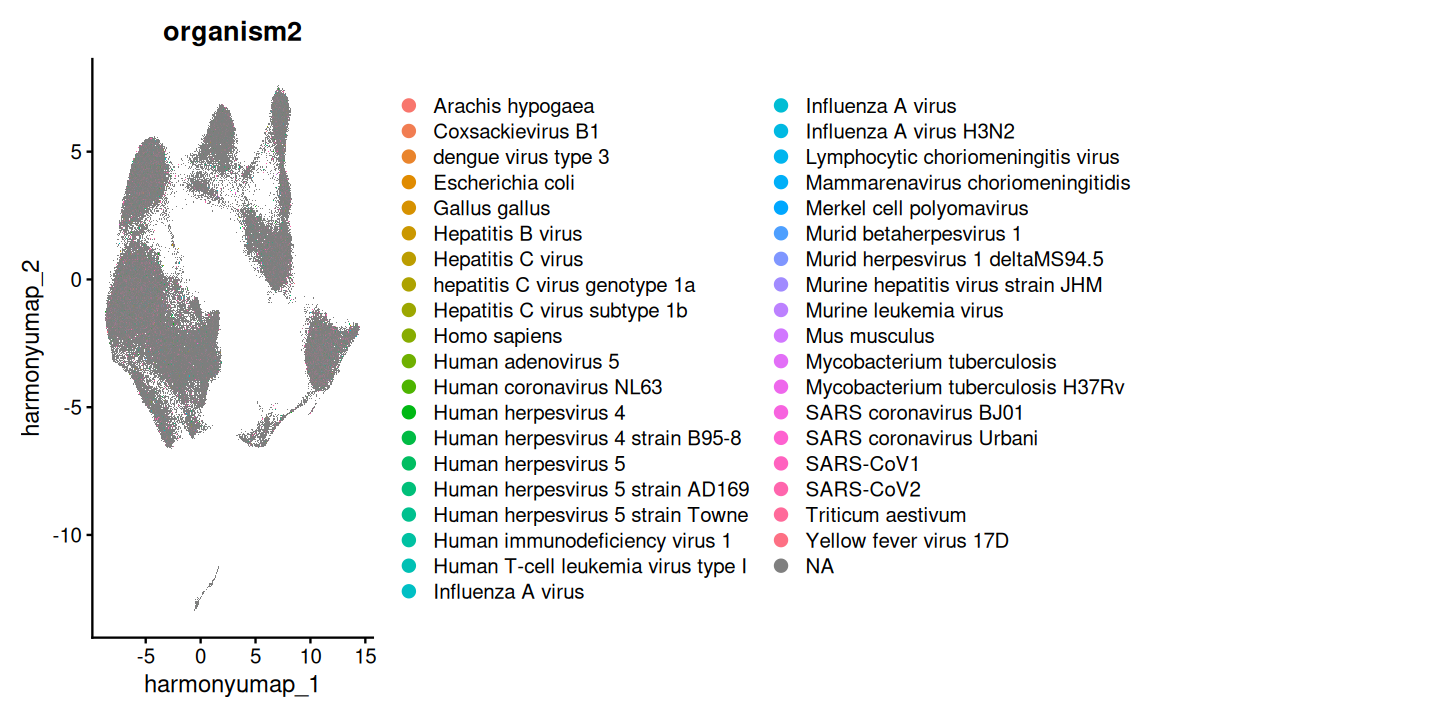

In [47]:
options(repr.plot.width = 12, repr.plot.height = 6)
DimPlot(seu, group.by = "organism2", ncol = 2, reduction = "harmony_umap")